# VARI confidence: from a drone photo to a VARI you can trust

This notebook runs the whole flow on one drone photo:

1. **Part A: segmentation and VARI.** This is the teammates' process from `segmentation/final_flow/notebook.ipynb`, with
   the logic unchanged. It finds the palm crowns, measures VARI on each tree, and groups the trees into zones.
2. **Part B: VARI confidence.** This is the weather rule from the "Status Cuaca Krops" page
   (`weather/l6_vari_confidence.py` on `feat/weather-vari-confidence`). It gives a score from 0 to 1 for how far this
   flight's VARI can be trusted as a sign of nutrient status.
3. **Part C: final output.** One JSON file that holds the zones, their VARI, and the flight's confidence.

```
photo ─► plant mask (ExG) ─► trees (YOLO) ─► VARI per tree ─► zones ─► zone VARI ──┐
                                                                                   ├─► final JSON
flight time + plot ─► sun · cloud · rain before · P30 (water) ─► confidence ───────┘
```

**Inputs**
- The photo and the Core ML model in `../segmentation/final_flow/`.
- The flight's start and end time, typed into the configuration cell. The photos carry no capture time.
- A `.env` with the WeatherKit keys and the plot's location (see `requirements.txt`).

**Outputs:** everything goes to `outputs/`, which git ignores:
- the teammates' images, JSON and CSV
- `<photo>_vari_confidence.json`, which holds everything

**To run:** install `requirements.txt` with Python 3.12 on macOS. WeatherKit and NASA POWER are fetched live, so an
internet connection is needed.

**Status:** the confidence is a **prototype**. Use it as a log and to rank scans, not yet to change recommendations.
Most factor values are still guesses, waiting for repeat flights to calibrate them. Only the P30 rule and the 25 mm
heavy-rain line are decided.

## Setup

### Imports
**What:** loads the libraries for both parts.

**Why:**
- Part A needs OpenCV, NumPy, Pillow, Matplotlib and coremltools.
- Part B needs only the standard library, `requests`, `pyjwt` (for WeatherKit's signed token) and `python-dotenv`.
- pandas only lays out tables.

Warnings from the weather sources are shown, for example when WeatherKit leaves out a day.

In [1]:
import calendar
import csv
import json
import logging
import math
import os
import time
from datetime import date, datetime, timedelta, timezone
from pathlib import Path
from statistics import median
from zoneinfo import ZoneInfo

import coremltools as ct
import cv2
import matplotlib.cm as cm
import matplotlib.colors as mcolors
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import requests
from dotenv import load_dotenv
from IPython.display import display
from matplotlib_inline.backend_inline import set_matplotlib_formats
from PIL import Image, ImageDraw, ImageFont

set_matplotlib_formats("jpeg")  # photos as JPEG keep the saved notebook small

logging.basicConfig(level=logging.WARNING, format="%(levelname)s %(name)s: %(message)s")
log = logging.getLogger("vari_confidence")

### Configuration
**What:** every setting in one place:
- which photo and model to use
- where the outputs go
- the teammates' detection and zoning numbers
- the flight being scored

**Why:**
- To run another photo or flight, change only this cell.
- The detection and zoning numbers are the teammates' values, unchanged.
- The flight time has to be typed in. The photos went through Roboflow, which strips the EXIF data that would hold the
  capture time.

> **The default flight is made up.** 15 Sep 2026, 09:40–10:05 WIB is the example on the "Status Cuaca Krops" page,
> not when `dji_15.jpg` was taken. Replace it with the real flight time.

The WeatherKit keys and the plot's location are read from a git-ignored `.env`, either next to this notebook or in
`../weather/`. The location is never printed, so it stays out of the saved notebook. Without a `.env`, the notebook
uses the trial plot's rounded location (the same default as `weather/krops_weather.py`) and runs without WeatherKit.

In [2]:
# --- The photo and the model (Part A) ---
IMAGE_PATH = "../segmentation/final_flow/dji_15.jpg"
MODEL_PATH = "../segmentation/final_flow/yolo26m-krops-v0.1.mlpackage"

OUT_DIR = Path("outputs")
OUT_DIR.mkdir(exist_ok=True)

# The teammates' output files, now inside outputs/
OUTPUT_JSON = str(OUT_DIR / "oil_palm_zones_vari.json")
OUTPUT_ZONE_CSV = str(OUT_DIR / "oil_palm_zone_vari_summary.csv")

OUTPUT_EXG_MASK = str(OUT_DIR / "oil_palm_exg_mask.png")
OUTPUT_EXG_SEGMENTED = str(OUT_DIR / "oil_palm_exg_segmented.jpg")
OUTPUT_COREML_ANNOTATED = str(OUT_DIR / "oil_palm_coreml_detections.jpg")
OUTPUT_ZONE_ANNOTATED = str(OUT_DIR / "oil_palm_zones_only.jpg")
OUTPUT_ANNOTATED_IMAGE = str(OUT_DIR / "oil_palm_zones_annotated.jpg")
OUTPUT_PIPELINE_PLOT = str(OUT_DIR / "oil_palm_pipeline_stages.jpg")

# The teammates' detection and zoning settings, unchanged
CONF_THRESHOLD = 0.25
IOU_THRESHOLD = 0.45
MODEL_INPUT_SIZE = 640

ZONE_GRID_ROWS = 3
ZONE_GRID_COLS = 3
TREES_PER_ZONE = ZONE_GRID_ROWS * ZONE_GRID_COLS
ROW_TOLERANCE_MULTIPLIER = 0.75

MAX_ZONE_DISTANCE_MULTIPLIER = 3.0
ZONE_PADDING_MULTIPLIER = 0.15

MIN_TREE_COMPLETENESS = 0.70  # Keep only trees >= 70% of typical tree size/area
BORDER_MARGIN_PX = 5

# --- The flight being scored (Part B) ---
WIB = ZoneInfo("Asia/Jakarta")
SCAN_ID = Path(IMAGE_PATH).stem
PLOT_ID = "tanjung-pinang-trial"
FLIGHT_START_WIB = datetime(2026, 9, 15, 9, 40, tzinfo=WIB)  # MADE UP: replace with the real take-off time
FLIGHT_END_WIB = datetime(2026, 9, 15, 10, 5, tzinfo=WIB)    # MADE UP: replace with the real landing time

# --- WeatherKit keys and the plot's location, from a git-ignored .env ---
ENV_FILE = next((p for p in (Path(".env"), Path("../weather/.env")) if p.is_file()), None)
if ENV_FILE:
    load_dotenv(ENV_FILE)
SITE_NAME = os.getenv("SITE_NAME", "Tanjung Pinang")
LAT = float(os.getenv("LAT", "0.92"))  # never printed: the plot's location stays out of the notebook
LON = float(os.getenv("LON", "104.45"))

print(f"Photo:  {IMAGE_PATH}")
print(f"Flight: {FLIGHT_START_WIB:%d %b %Y %H:%M}–{FLIGHT_END_WIB:%H:%M} WIB at {SITE_NAME}")
print(f".env:   {ENV_FILE or 'none found: WeatherKit off, the trial plot rounded location'}")

Photo:  ../segmentation/final_flow/dji_15.jpg
Flight: 15 Sep 2026 09:40–10:05 WIB at Tanjung Pinang
.env:   ../weather/.env


# Part A: segmentation and VARI (the teammates' process)

The code in this part is copied from `segmentation/final_flow/notebook.ipynb` on master, and the logic is unchanged.
The teammates ran everything inside one `main()`. Here the body of `main()` is split into steps, and each step sits
with the functions it uses.

Cosmetic changes only:
- The outputs go to `outputs/`.
- Pictures are shown along the way, and the output list prints relative paths.
- One leftover slice, `zx1:zy2 if False else zx2`, is written as `zx1:zx2`, which is what it always evaluated to.

## A1. Separate plants from soil (Excess Green)
**What:**
- Each pixel gets a greenness score, *Excess Green*: ExG = 2G − R − B.
- The scores are stretched to 0–255, and Otsu's method picks the cut-off between plant and soil for this photo.
- A small 3×3 opening and closing removes specks and fills pinholes.
- The result is a plant mask and a copy of the photo with the soil blacked out.

**Why:**
- VARI should be measured on leaves only; soil would pull it down.
- The soil-free image is also what the tree detector sees in A2.

1/6: Loading image and running ExG segmentation...


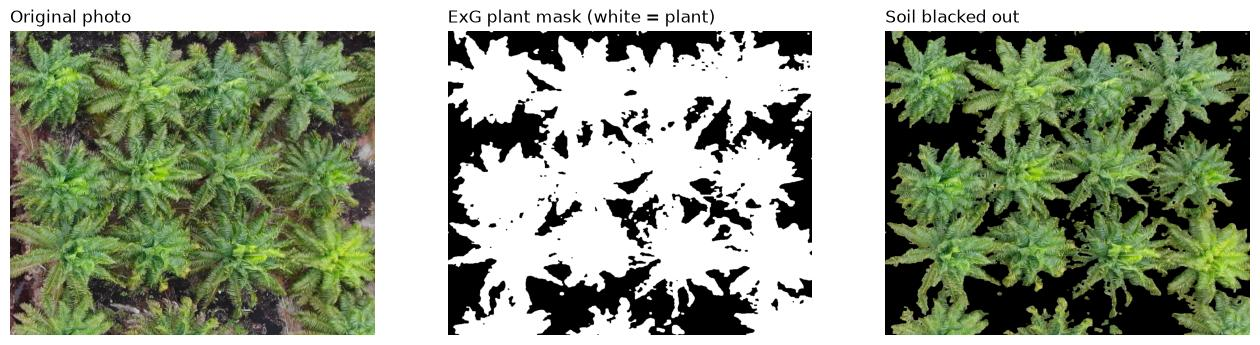

1042 × 869 px · plant pixels: 66% of the photo


In [3]:
# From segmentation/final_flow/notebook.ipynb on master (97fbbf5); logic unchanged.
def segment_vegetation_exg(image_bgr):
    """Create an ExG/Otsu mask. This is a heuristic vegetation mask, not a crown model."""
    b, g, r = cv2.split(image_bgr)
    exg = 2.0 * g.astype(np.float32) - r.astype(np.float32) - b.astype(np.float32)
    exg_u8 = cv2.normalize(exg, None, 0, 255, cv2.NORM_MINMAX).astype(np.uint8)
    _, mask = cv2.threshold(exg_u8, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
    kernel = np.ones((3, 3), np.uint8)
    mask = cv2.morphologyEx(mask, cv2.MORPH_OPEN, kernel, iterations=1)
    mask = cv2.morphologyEx(mask, cv2.MORPH_CLOSE, kernel, iterations=1)
    segmented = cv2.bitwise_and(image_bgr, image_bgr, mask=mask)
    return mask, segmented


image_path = Path(IMAGE_PATH)
model_path = Path(MODEL_PATH)
if not image_path.exists():
    raise FileNotFoundError(f"Image not found: {image_path.resolve()}")
if not model_path.exists():
    raise FileNotFoundError(f"CoreML model not found: {model_path.resolve()}")

print("1/6: Loading image and running ExG segmentation...")
original_bgr = cv2.imread(str(image_path), cv2.IMREAD_COLOR)
if original_bgr is None:
    raise ValueError(f"Could not read image: {image_path}")
height, width = original_bgr.shape[:2]
original_rgb = cv2.cvtColor(original_bgr, cv2.COLOR_BGR2RGB)
exg_mask, segmented_bgr = segment_vegetation_exg(original_bgr)
segmented_rgb = cv2.cvtColor(segmented_bgr, cv2.COLOR_BGR2RGB)

cv2.imwrite(OUTPUT_EXG_MASK, exg_mask)
cv2.imwrite(OUTPUT_EXG_SEGMENTED, segmented_bgr)


fig, axes = plt.subplots(1, 3, figsize=(16, 4.6))
for ax, img, title in zip(axes, (original_rgb, exg_mask, segmented_rgb),
                          ("Original photo", "ExG plant mask (white = plant)", "Soil blacked out")):
    ax.imshow(img, cmap="gray" if img.ndim == 2 else None)
    ax.set_title(title, loc="left")
    ax.axis("off")
plt.show()
print(f"{width} × {height} px · plant pixels: {(exg_mask > 0).mean():.0%} of the photo")

## A2. Find the trees (Core ML YOLO)
**What:**
- The soil-free image is resized to 640 × 640 and run through `yolo26m-krops-v0.1`.
- Each detection is `[centre x, centre y, width, height, confidence]`.
- Detections under 0.25 confidence are dropped. Overlapping duplicates are removed with non-maximum suppression: of two
  boxes overlapping more than 0.45 IoU, the weaker one goes.
- The boxes are scaled back to the photo's pixels.

**Why:** VARI is reported per tree and per zone, so the trees have to be found first. The model returns one box per
palm crown.

In [4]:
# From segmentation/final_flow/notebook.ipynb on master (97fbbf5); logic unchanged.
def iou(box1, box2):
    x1, y1 = max(box1[0], box2[0]), max(box1[1], box2[1])
    x2, y2 = min(box1[2], box2[2]), min(box1[3], box2[3])
    inter = max(0, x2 - x1) * max(0, y2 - y1)
    area1 = max(0, box1[2] - box1[0]) * max(0, box1[3] - box1[1])
    area2 = max(0, box2[2] - box2[0]) * max(0, box2[3] - box2[1])
    union = area1 + area2 - inter
    return inter / union if union > 0 else 0.0


def nms(boxes, scores, iou_threshold=0.45):
    if not boxes:
        return []
    order = np.argsort(scores)[::-1]
    selected = []
    while len(order) > 0:
        current = int(order[0])
        selected.append(current)
        order = np.asarray([
            int(j) for j in order[1:]
            if iou(boxes[current], boxes[int(j)]) <= iou_threshold
        ], dtype=int)
    return selected


def parse_coreml_predictions(model, rgb_image):
    """Parse the [1, 5, N] / [1, N, 5] single-class output assumed by the source script.

    Expected prediction rows: [cx, cy, width, height, confidence] in 640x640 pixels.
    """
    input_names = list(model.input_description)
    if not input_names:
        raise RuntimeError("The CoreML model has no declared input.")
    pil_image = Image.fromarray(rgb_image).convert("RGB").resize(
        (MODEL_INPUT_SIZE, MODEL_INPUT_SIZE)
    )
    prediction = model.predict({input_names[0]: pil_image})
    output_key = list(prediction.keys())[0]
    raw = np.asarray(prediction[output_key])
    raw = np.squeeze(raw)

    if raw.ndim != 2:
        raise ValueError(f"Unexpected model output shape {raw.shape}; expected a 2D array after squeeze.")
    if raw.shape[0] == 5:
        rows = raw.T
    elif raw.shape[1] == 5:
        rows = raw
    else:
        raise ValueError(
            f"Model output shape {raw.shape} does not have a 5-value detection axis. "
            "Inspect the CoreML output schema and update parse_coreml_predictions()."
        )

    boxes, scores = [], []
    for row in rows:
        cx, cy, width, height, confidence = map(float, row[:5])
        if not np.isfinite([cx, cy, width, height, confidence]).all() or confidence < CONF_THRESHOLD:
            continue
        box = [
            np.clip((cx - width / 2) / MODEL_INPUT_SIZE, 0, 1),
            np.clip((cy - height / 2) / MODEL_INPUT_SIZE, 0, 1),
            np.clip((cx + width / 2) / MODEL_INPUT_SIZE, 0, 1),
            np.clip((cy + height / 2) / MODEL_INPUT_SIZE, 0, 1),
        ]
        if box[2] > box[0] and box[3] > box[1]:
            boxes.append([float(v) for v in box])
            scores.append(confidence)

    keep = nms(boxes, scores, IOU_THRESHOLD)
    return [boxes[i] for i in keep], [scores[i] for i in keep]


def normalized_box_to_pixels(box, width, height):
    x1, y1, x2, y2 = box
    return [
        max(0, min(width, int(round(x1 * width)))),
        max(0, min(height, int(round(y1 * height)))),
        max(0, min(width, int(round(x2 * width)))),
        max(0, min(height, int(round(y2 * height)))),
    ]


print("2/6: Loading CoreML model and detecting trees on ExG-segmented image...")
model = ct.models.MLModel(str(model_path))
normalized_boxes, scores = parse_coreml_predictions(model, segmented_rgb)
raw_trees = []
for box, score in zip(normalized_boxes, scores):
    bbox = normalized_box_to_pixels(box, width, height)
    bw, bh = bbox[2] - bbox[0], bbox[3] - bbox[1]
    if bw <= 0 or bh <= 0:
        continue
    raw_trees.append({
        "confidence": float(score),
        "bbox": bbox,
        "width": bw,
        "height": bh,
        "area": bw * bh,
        "center": ((bbox[0] + bbox[2]) / 2.0, (bbox[1] + bbox[3]) / 2.0),
        "bbox_normalized": [bbox[0] / width, bbox[1] / height, bbox[2] / width, bbox[3] / height],
    })

print(f"{len(raw_trees)} detections above {CONF_THRESHOLD} confidence after NMS")

2/6: Loading CoreML model and detecting trees on ExG-segmented image...


15 detections above 0.25 confidence after NMS


## A3. Drop trees cut off by the photo's edge
**What:**
- The typical tree size is the median width, height and area of the trees that don't touch the photo's border
  (5 px margin).
- A tree under 70% of that width, height or area is dropped.
- The trees that remain are numbered `T1, T2, …`.

**Why:** a crown cut in half by the edge would give a VARI from only part of the tree.

In [5]:
# From segmentation/final_flow/notebook.ipynb on master (97fbbf5); logic unchanged.
# Reference full-tree size from interior trees (not clipped by image borders)
interior_trees = [
    t for t in raw_trees
    if t["bbox"][0] > BORDER_MARGIN_PX
    and t["bbox"][1] > BORDER_MARGIN_PX
    and t["bbox"][2] < (width - BORDER_MARGIN_PX)
    and t["bbox"][3] < (height - BORDER_MARGIN_PX)
]
ref_pool = interior_trees if interior_trees else raw_trees

if ref_pool:
    median_w = float(np.median([t["width"] for t in ref_pool]))
    median_h = float(np.median([t["height"] for t in ref_pool]))
    median_area = float(np.median([t["area"] for t in ref_pool]))
else:
    median_w = median_h = median_area = 0.0

# Keep only trees that are at least 70% of typical width, height, and area
trees = []
skipped_partial = 0
for t in raw_trees:
    w_ratio = t["width"] / median_w if median_w > 0 else 1.0
    h_ratio = t["height"] / median_h if median_h > 0 else 1.0
    area_ratio = t["area"] / median_area if median_area > 0 else 1.0

    if (
        w_ratio < MIN_TREE_COMPLETENESS
        or h_ratio < MIN_TREE_COMPLETENESS
        or area_ratio < MIN_TREE_COMPLETENESS
    ):
        skipped_partial += 1
        continue

    t["tree_id"] = len(trees) + 1
    trees.append(t)

print(
    f"Detected {len(trees)} valid trees (>= {int(MIN_TREE_COMPLETENESS * 100)}% size); "
    f"filtered out {skipped_partial} partial/half trees."
)

Detected 12 valid trees (>= 70% size); filtered out 3 partial/half trees.


## A4. VARI per pixel and per tree
**What:**
- VARI = (G − R) / (G + R − B) is computed for every pixel of the original photo. Pixels where G + R − B is 0 are left
  empty.
- Each tree's statistics use the pixels inside its box that the ExG mask marks as plant: count, mean, median,
  standard deviation, MAD, min and max.

**Why:**
- VARI (Visible Atmospherically Resistant Index) needs only an RGB camera. Greener leaves score higher.
- The median is the number to read. The min and max come from a handful of extreme pixels.

In [6]:
# From segmentation/final_flow/notebook.ipynb on master (97fbbf5); logic unchanged.
def stats_for_box(vari_map, exg_mask, bbox):
    x1, y1, x2, y2 = bbox
    if x2 <= x1 or y2 <= y1:
        values = np.asarray([], dtype=np.float32)
    else:
        vari_crop = vari_map[y1:y2, x1:x2]
        mask_crop = exg_mask[y1:y2, x1:x2] > 0
        values = vari_crop[mask_crop & np.isfinite(vari_crop)]

    if values.size == 0:
        return {
            "vegetation_pixel_count": 0,
            "mean_vari": None,
            "median_vari": None,
            "std_vari": None,
            "mad_vari": None,
            "min_vari": None,
            "max_vari": None,
        }
    median = float(np.median(values))
    return {
        "vegetation_pixel_count": int(values.size),
        "mean_vari": float(np.mean(values)),
        "median_vari": median,
        "std_vari": float(np.std(values)),
        "mad_vari": float(np.median(np.abs(values - median))),
        "min_vari": float(np.min(values)),
        "max_vari": float(np.max(values)),
    }


def pixel_bbox_record(bbox, image_width, image_height):
    x1, y1, x2, y2 = map(int, bbox)
    return {
        "x1": x1, "y1": y1, "x2": x2, "y2": y2,
        "width": x2 - x1,
        "height": y2 - y1,
        "normalized_xyxy": [
            x1 / image_width, y1 / image_height,
            x2 / image_width, y2 / image_height,
        ],
    }


print("3/6: Calculating VARI map and tree-level statistics...")
b, g, r = cv2.split(original_bgr)
b = b.astype(np.float32)
g = g.astype(np.float32)
r = r.astype(np.float32)
denominator = g + r - b
vari_map = np.full((height, width), np.nan, dtype=np.float32)
valid = np.isfinite(denominator) & (np.abs(denominator) > 1e-6)
np.divide(g - r, denominator, out=vari_map, where=valid)

for tree in trees:
    tree["vari"] = stats_for_box(vari_map, exg_mask, tree["bbox"])
    tree["bbox_annotation"] = pixel_bbox_record(tree["bbox"], width, height)

display(pd.DataFrame([
    {"tree": f"T{t['tree_id']}", "detector confidence": t["confidence"], "plant pixels": t["vari"]["vegetation_pixel_count"],
     "median VARI": t["vari"]["median_vari"], "mean VARI": t["vari"]["mean_vari"], "std VARI": t["vari"]["std_vari"]}
    for t in trees
]).set_index("tree").round(3))

3/6: Calculating VARI map and tree-level statistics...


,detector confidence,plant pixels,median VARI,mean VARI,std VARI
tree,,,,,
T1,0.873,47679,0.199,0.207,0.086
T2,0.866,56014,0.123,0.126,0.052
T3,0.858,55339,0.201,0.210,0.098
T4,0.852,48093,0.180,0.189,0.097
T5,0.852,40811,0.168,0.169,0.071
T6,0.849,79116,0.160,0.170,0.069
T7,0.836,63499,0.171,0.181,0.078
T8,0.835,57896,0.157,0.168,0.084
T9,0.833,55245,0.170,0.180,0.091


## A5. Group the trees into zones of up to 3 × 3
**What:**
- **Rows.** Trees are grouped into rows by their vertical position. A tree joins a row when its centre is within
  0.75 × the median tree height of that row.
- **Bands.** Every 3 rows make a band. A band also ends where two rows are more than 3 tree heights apart.
- **Zones.** Within a band, the trees are sorted left to right and cut into groups of up to 9. A gap wider than
  3 tree heights also starts a new group.
- A zone's area is the rectangle around its trees, plus a little padding.

**Why:** a zone sums up a small block of neighbouring palms. That is easier to act on in the field than single trees,
and steadier than one tree's VARI.

In [7]:
# From segmentation/final_flow/notebook.ipynb on master (97fbbf5); logic unchanged.
def group_trees_into_zones(
    trees,
    grid_rows=3,
    grid_cols=3,
    row_tolerance_multiplier=0.75,
    max_zone_distance_multiplier=3.0,
    zone_padding_multiplier=0.15,
    image_width=None,
    image_height=None,
):
    """Group nearby palm trees into 3x3 spatial blocks (3 rows x 3 columns, up to 9 trees)."""
    if grid_rows < 1 or grid_cols < 1:
        raise ValueError("grid_rows and grid_cols must be at least 1.")

    if not trees:
        return []

    target_trees_per_zone = grid_rows * grid_cols

    # 1. Estimate typical tree size
    heights = [max(1, tree["bbox"][3] - tree["bbox"][1]) for tree in trees]
    median_height = float(np.median(heights))

    row_tolerance = max(1.0, median_height * row_tolerance_multiplier)
    max_zone_distance = max(1.0, median_height * max_zone_distance_multiplier)
    padding = max(0, int(median_height * zone_padding_multiplier))

    # 2. Cluster trees into approximate horizontal rows
    ordered = sorted(trees, key=lambda tree: (tree["center"][1], tree["center"][0]))
    rows = []

    for tree in ordered:
        cy = tree["center"][1]
        best_row = None
        best_distance = float("inf")

        for row in rows:
            row_center = float(np.median([item["center"][1] for item in row]))
            distance = abs(cy - row_center)
            if distance <= row_tolerance and distance < best_distance:
                best_row = row
                best_distance = distance

        if best_row is None:
            rows.append([tree])
        else:
            best_row.append(tree)

    rows.sort(key=lambda row: float(np.median([tree["center"][1] for tree in row])))
    for row in rows:
        row.sort(key=lambda tree: tree["center"][0])

    # 3. Group consecutive rows into bands of up to `grid_rows` (3 rows)
    row_bands = []
    current_band = []

    for row in rows:
        if not current_band:
            current_band.append(row)
        else:
            prev_row_y = float(np.median([t["center"][1] for t in current_band[-1]]))
            curr_row_y = float(np.median([t["center"][1] for t in row]))
            if len(current_band) >= grid_rows or (curr_row_y - prev_row_y) > max_zone_distance:
                row_bands.append(current_band)
                current_band = [row]
            else:
                current_band.append(row)

    if current_band:
        row_bands.append(current_band)

    # 4. Within each 3-row band, slice horizontally into 3-column blocks (up to 9 trees)
    zones = []

    for band_idx, band in enumerate(row_bands, start=1):
        band_trees = [tree for row in band for tree in row]
        band_trees.sort(key=lambda t: t["center"][0])

        # Split horizontally if there is a wide gap (e.g., road/clearing)
        spatial_clusters = []
        current_cluster = [band_trees[0]]

        for tree in band_trees[1:]:
            dx = tree["center"][0] - current_cluster[-1]["center"][0]
            if dx <= max_zone_distance:
                current_cluster.append(tree)
            else:
                spatial_clusters.append(current_cluster)
                current_cluster = [tree]
        spatial_clusters.append(current_cluster)

        # Slice each contiguous horizontal cluster into 3x3 blocks
        for cluster in spatial_clusters:
            block_capacity = len(band) * grid_cols  # 3 cols per row in the current band

            for offset in range(0, len(cluster), block_capacity):
                members = cluster[offset:offset + block_capacity]

                x1 = min(t["bbox"][0] for t in members) - padding
                y1 = min(t["bbox"][1] for t in members) - padding
                x2 = max(t["bbox"][2] for t in members) + padding
                y2 = max(t["bbox"][3] for t in members) + padding

                if image_width is not None:
                    x1 = max(0, x1)
                    x2 = min(image_width, x2)
                if image_height is not None:
                    y1 = max(0, y1)
                    y2 = min(image_height, y2)

                zones.append({
                    "zone_id": len(zones) + 1,
                    "approx_row": band_idx,
                    "trees": members,
                    "bbox": [x1, y1, x2, y2],
                    "is_undersized": len(members) < target_trees_per_zone,
                })

    return zones


print(f"4/6: Grouping trees into {ZONE_GRID_ROWS}x{ZONE_GRID_COLS} zones (up to {TREES_PER_ZONE} trees/zone)...")
zones = group_trees_into_zones(
    trees,
    grid_rows=ZONE_GRID_ROWS,
    grid_cols=ZONE_GRID_COLS,
    row_tolerance_multiplier=ROW_TOLERANCE_MULTIPLIER,
    max_zone_distance_multiplier=MAX_ZONE_DISTANCE_MULTIPLIER,
    zone_padding_multiplier=ZONE_PADDING_MULTIPLIER,
    image_width=width,
    image_height=height,
)

for zone in zones:
    print(f"Zone {zone['zone_id']}: {len(zone['trees'])} trees, row band {zone['approx_row']}")

4/6: Grouping trees into 3x3 zones (up to 9 trees/zone)...
Zone 1: 9 trees, row band 1
Zone 2: 3 trees, row band 1


## A6. Draw the detections
**What:** draws each kept tree's box and detector confidence on the soil-free image.

**Why:** to check by eye that the detector found every palm and nothing else. This is panel 3 of the figure in A11.

In [8]:
# From segmentation/final_flow/notebook.ipynb on master (97fbbf5); logic unchanged.
print("5/6: Coloring ExG tree masks by zone and calculating zone statistics...")
try:
    font = ImageFont.truetype("Arial.ttf", max(12, min(24, width // 100)))
except OSError:
    font = ImageFont.load_default()

tree_line_width = max(2, width // 1500)
MASK_OVERLAY_ALPHA = 0.60

# Image 3: CoreML object detections drawn on the ExG-segmented RGB image
coreml_on_exg_img = Image.fromarray(segmented_rgb.copy())
draw_coreml_exg = ImageDraw.Draw(coreml_on_exg_img)
for tree in trees:
    tb = tree["bbox"]
    draw_coreml_exg.rectangle(tb, outline=(255, 40, 40), width=tree_line_width)
    tree_label = f"T{tree['tree_id']} {tree['confidence']:.2f}"
    tx, ty = tb[0], max(0, tb[1] - 18)
    draw_coreml_exg.text(
        (tx, ty), tree_label,
        fill=(255, 255, 255), stroke_width=2, stroke_fill=(150, 0, 0), font=font
    )
coreml_on_exg_img.save(OUTPUT_COREML_ANNOTATED, quality=95)

5/6: Coloring ExG tree masks by zone and calculating zone statistics...


## A7. Zone VARI and zone colours
**What:** for each zone:
- Its trees' plant pixels are painted in the zone's colour, on a black canvas and on the original photo.
- The zone's VARI is computed from the plant pixels inside any of its trees' boxes, with the same statistics as per
  tree.
- The zone's record is built: its box, its VARI, and its trees with theirs.

**Why:** the zone's VARI should describe its palms. It leaves out the vegetation between the trees' boxes, such as
weeds.

In [9]:
# From segmentation/final_flow/notebook.ipynb on master (97fbbf5); logic unchanged.
# Image 4a: Black canvas where ONLY detected tree ExG mask pixels are colored by Zone ID
zone_tree_mask_rgb = np.zeros_like(original_rgb)

# Image 4b: Original WebODM image where detected tree ExG mask pixels are blended by Zone ID
zone_tree_overlay_rgb = original_rgb.copy()

cmap_zones = plt.colormaps["tab20"]
zone_label_positions = []
zone_json = []

for zone in zones:
    zb = zone["bbox"]
    zx1, zy1, zx2, zy2 = zb
    tree_records = []

    # Pick a unique RGB color for this zone
    rgba = cmap_zones((zone["zone_id"] - 1) % 20 / 20.0)
    zone_color_u8 = np.array([int(round(c * 255)) for c in rgba[:3]], dtype=np.uint8)
    zone_color = tuple(int(v) for v in zone_color_u8)

    # Union mask of member tree boxes so Zone VARI only uses member tree ExG pixels
    tree_box_union = np.zeros((zy2 - zy1, zx2 - zx1), dtype=bool)

    for tree in zone["trees"]:
        tx1, ty1, tx2, ty2 = tree["bbox"]
        tree_records.append({
            "tree_id": tree["tree_id"],
            "confidence": tree["confidence"],
            "bbox": tree["bbox_annotation"],
            "vari": tree["vari"],
        })

        # Get ExG mask pixels inside this tree's detection area
        tree_exg_mask = exg_mask[ty1:ty2, tx1:tx2] > 0

        # 1) Color the tree's ExG mask pixels on the black canvas
        zone_tree_mask_rgb[ty1:ty2, tx1:tx2][tree_exg_mask] = zone_color_u8

        # 2) Alpha-blend the zone color onto the tree's ExG mask pixels on the original image
        orig_crop = zone_tree_overlay_rgb[ty1:ty2, tx1:tx2]
        orig_crop[tree_exg_mask] = (
            orig_crop[tree_exg_mask].astype(np.float32) * (1.0 - MASK_OVERLAY_ALPHA)
            + zone_color_u8.astype(np.float32) * MASK_OVERLAY_ALPHA
        ).astype(np.uint8)

        # Mark this tree's region inside the zone union mask
        lx1, ly1 = max(0, tx1 - zx1), max(0, ty1 - zy1)
        lx2, ly2 = min(zx2 - zx1, tx2 - zx1), min(zy2 - zy1, ty2 - zy1)
        if lx2 > lx1 and ly2 > ly1:
            tree_box_union[ly1:ly2, lx1:lx2] = True

    # Calculate Zone VARI strictly from the colored ExG tree pixels in this zone
    vari_crop = vari_map[zy1:zy2, zx1:zx2]
    mask_crop = (exg_mask[zy1:zy2, zx1:zx2] > 0) & tree_box_union
    valid_vals = vari_crop[mask_crop & np.isfinite(vari_crop)]
    if valid_vals.size == 0:
        zone_stats = {
            "vegetation_pixel_count": 0,
            "mean_vari": None, "median_vari": None,
            "std_vari": None, "mad_vari": None,
            "min_vari": None, "max_vari": None,
        }
    else:
        med = float(np.median(valid_vals))
        zone_stats = {
            "vegetation_pixel_count": int(valid_vals.size),
            "mean_vari": float(np.mean(valid_vals)),
            "median_vari": med,
            "std_vari": float(np.std(valid_vals)),
            "mad_vari": float(np.median(np.abs(valid_vals - med))),
            "min_vari": float(np.min(valid_vals)),
            "max_vari": float(np.max(valid_vals)),
        }

    zone_label = f"Z{zone['zone_id']} (n={len(tree_records)})"
    zx, zy = zx1, max(0, zy1 - 28)
    zone_label_positions.append((zx, zy, zone_label, zone_color))

    zone_json.append({
        "zone_id": zone["zone_id"],
        "approx_row": zone["approx_row"],
        "tree_count": len(tree_records),
        "bbox": pixel_bbox_record(zb, width, height),
        "vari": zone_stats,
        "trees": tree_records,
    })

## A8. Label the zone images
**What:** writes each zone's name and tree count, for example `Z1 (n=9)`, on the two zone images, then saves them.

**Why:** the labels link the pictures to the rows of the tables below.

In [10]:
# From segmentation/final_flow/notebook.ipynb on master (97fbbf5); logic unchanged.
zones_only_img = Image.fromarray(zone_tree_mask_rgb)
draw_zones_only = ImageDraw.Draw(zones_only_img)

combined_annotated_img = Image.fromarray(zone_tree_overlay_rgb)
draw_combined = ImageDraw.Draw(combined_annotated_img)

# Draw only the Zone ID text labels (no bounding boxes)
for zx, zy, zone_label, zone_color in zone_label_positions:
    for canvas in (draw_zones_only, draw_combined):
        canvas.text(
            (zx, zy), zone_label,
            fill=zone_color, stroke_width=2, stroke_fill=(0, 0, 0), font=font
        )

zones_only_img.save(OUTPUT_ZONE_ANNOTATED, quality=95)
combined_annotated_img.save(OUTPUT_ANNOTATED_IMAGE, quality=95)

## A9. Zone table and CSV
**What:** prints one row per zone with its VARI statistics, and saves the same rows to CSV.

**Why:** this is the teammates' summary of the photo. Read the median VARI column.

In [11]:
# From segmentation/final_flow/notebook.ipynb on master (97fbbf5); logic unchanged.
def print_zone_vari_table(zone_json):
    """Print a compact table containing VARI statistics for each zone."""
    columns = [
        ("zone_id", "Zone"),
        ("tree_count", "Trees"),
        ("vegetation_pixel_count", "Valid pixels"),
        ("mean_vari", "Mean VARI"),
        ("median_vari", "Median VARI"),
        ("std_vari", "Std VARI"),
        ("mad_vari", "MAD VARI"),
        ("min_vari", "Min VARI"),
        ("max_vari", "Max VARI"),
    ]

    def fmt(value, digits=4):
        if value is None:
            return "N/A"
        if isinstance(value, (int, np.integer)):
            return f"{value:,}"
        if isinstance(value, (float, np.floating)):
            return f"{value:.{digits}f}" if np.isfinite(value) else "N/A"
        return str(value)

    rows = []
    for zone in zone_json:
        stats = zone.get("vari", {})
        row = {
            "zone_id": zone.get("zone_id"),
            "tree_count": zone.get("tree_count"),
            "vegetation_pixel_count": stats.get("vegetation_pixel_count"),
            "mean_vari": stats.get("mean_vari"),
            "median_vari": stats.get("median_vari"),
            "std_vari": stats.get("std_vari"),
            "mad_vari": stats.get("mad_vari"),
            "min_vari": stats.get("min_vari"),
            "max_vari": stats.get("max_vari"),
        }
        rows.append([fmt(row[key]) for key, _ in columns])

    widths = [
        max(len(header), *(len(row[i]) for row in rows)) if rows else len(header)
        for i, (_, header) in enumerate(columns)
    ]
    header_line = " | ".join(header.ljust(widths[i]) for i, (_, header) in enumerate(columns))
    separator = "-+-".join("-" * width for width in widths)

    print("\n--- Zone VARI Summary ---")
    print(header_line)
    print(separator)
    if not rows:
        print("(No zones were created.)")
    else:
        for row in rows:
            print(" | ".join(value.ljust(widths[i]) for i, value in enumerate(row)))


def save_zone_vari_csv(zone_json, output_path):
    """Save one row per zone with VARI statistics to CSV."""
    fieldnames = [
        "zone_id",
        "approx_row",
        "tree_count",
        "bbox_x1",
        "bbox_y1",
        "bbox_x2",
        "bbox_y2",
        "vegetation_pixel_count",
        "mean_vari",
        "median_vari",
        "std_vari",
        "mad_vari",
        "min_vari",
        "max_vari",
    ]

    with open(output_path, "w", newline="", encoding="utf-8") as csv_file:
        writer = csv.DictWriter(csv_file, fieldnames=fieldnames)
        writer.writeheader()
        for zone in zone_json:
            bbox = zone.get("bbox", {})
            stats = zone.get("vari", {})
            writer.writerow({
                "zone_id": zone.get("zone_id"),
                "approx_row": zone.get("approx_row"),
                "tree_count": zone.get("tree_count"),
                "bbox_x1": bbox.get("x1"),
                "bbox_y1": bbox.get("y1"),
                "bbox_x2": bbox.get("x2"),
                "bbox_y2": bbox.get("y2"),
                "vegetation_pixel_count": stats.get("vegetation_pixel_count"),
                "mean_vari": stats.get("mean_vari"),
                "median_vari": stats.get("median_vari"),
                "std_vari": stats.get("std_vari"),
                "mad_vari": stats.get("mad_vari"),
                "min_vari": stats.get("min_vari"),
                "max_vari": stats.get("max_vari"),
            })


# Save CSV and print summary table
save_zone_vari_csv(zone_json, OUTPUT_ZONE_CSV)
print_zone_vari_table(zone_json)


--- Zone VARI Summary ---
Zone | Trees | Valid pixels | Mean VARI | Median VARI | Std VARI | MAD VARI | Min VARI | Max VARI
-----+-------+--------------+-----------+-------------+----------+----------+----------+---------
1    | 9     | 416,855      | 0.1912    | 0.1810      | 0.0870   | 0.0503   | -0.0586  | 1.1026  
2    | 3     | 157,485      | 0.1590    | 0.1512      | 0.0720   | 0.0420   | -0.0400  | 0.9649  


## A10. The teammates' JSON
**What:** saves to `outputs/oil_palm_zones_vari.json`:
- the photo's metadata: method, thresholds and limitations
- every zone with its box, its VARI and its trees

**Why:** this is master's output format, unchanged. Part C adds the confidence to it.

In [12]:
# From segmentation/final_flow/notebook.ipynb on master (97fbbf5); logic unchanged.
# Save JSON
result = {
    "metadata": {
        "source_image": str(image_path),
        "image_width_px": width,
        "image_height_px": height,
        "exg_method": "ExG = 2G - R - B; min-max normalized; Otsu threshold; 3x3 opening/closing",
        "vari_formula": "(G - R) / (G + R - B)",
        "vari_pixel_filter": "Only finite VARI pixels with non-zero denominator inside ExG mask are included",
        "model_path": str(model_path),
        "confidence_threshold": CONF_THRESHOLD,
        "nms_iou_threshold": IOU_THRESHOLD,
        "trees_per_zone_max": TREES_PER_ZONE,
        "zone_grouping": "Approximate image-row clustering, then left-to-right chunks; each zone is the rectangle enclosing its member tree boxes",
        "row_tolerance_multiplier": ROW_TOLERANCE_MULTIPLIER,
        "detected_tree_count": len(trees),
        "zone_count": len(zone_json),
        "coordinate_system": "Pixel coordinates use origin (0,0) at top-left; bbox x1,y1 inclusive-ish and x2,y2 exclusive crop boundary. normalized_xyxy values are divided by original image width/height.",
        "limitations": [
            "ExG is a heuristic vegetation mask and may include weeds or omit shaded palm leaves.",
            "Zone rectangles are generated from spatial grouping of detected trees; they are not guaranteed to match actual plantation blocks or planting rows.",
            "Zone VARI summarizes the entire rectangular zone's ExG-selected pixels, which may include vegetation between tree boxes. Use tree-only aggregation instead if that is the intended zone definition.",
            "VARI is an RGB vegetation index, not a direct diagnosis of palm health or fertilizer requirement.",
        ],
    },
    "zones": zone_json,
}
with open(OUTPUT_JSON, "w", encoding="utf-8") as f:
    json.dump(result, f, indent=2, ensure_ascii=False, allow_nan=False)

## A11. Six-panel figure
**What:** the pipeline in one picture, in six panels:
1. the original photo
2. the soil blacked out
3. the detections
4. the zones only
5. the zones on the photo
6. a zone VARI table, coloured from −1 to +1

**Why:** one picture to check that every stage worked.


6/6: Outputs written:
  1. ExG mask:                 outputs/oil_palm_exg_mask.png
  2. ExG-segmented RGB:        outputs/oil_palm_exg_segmented.jpg
  3. Detections on ExG image:  outputs/oil_palm_coreml_detections.jpg
  4. Zones only (on original): outputs/oil_palm_zones_only.jpg
  5. Zones + trees (original): outputs/oil_palm_zones_annotated.jpg
  6. 6-Panel comparison plot:  outputs/oil_palm_pipeline_stages.jpg
  7. JSON output:              outputs/oil_palm_zones_vari.json
  8. Zone VARI CSV:            outputs/oil_palm_zone_vari_summary.csv


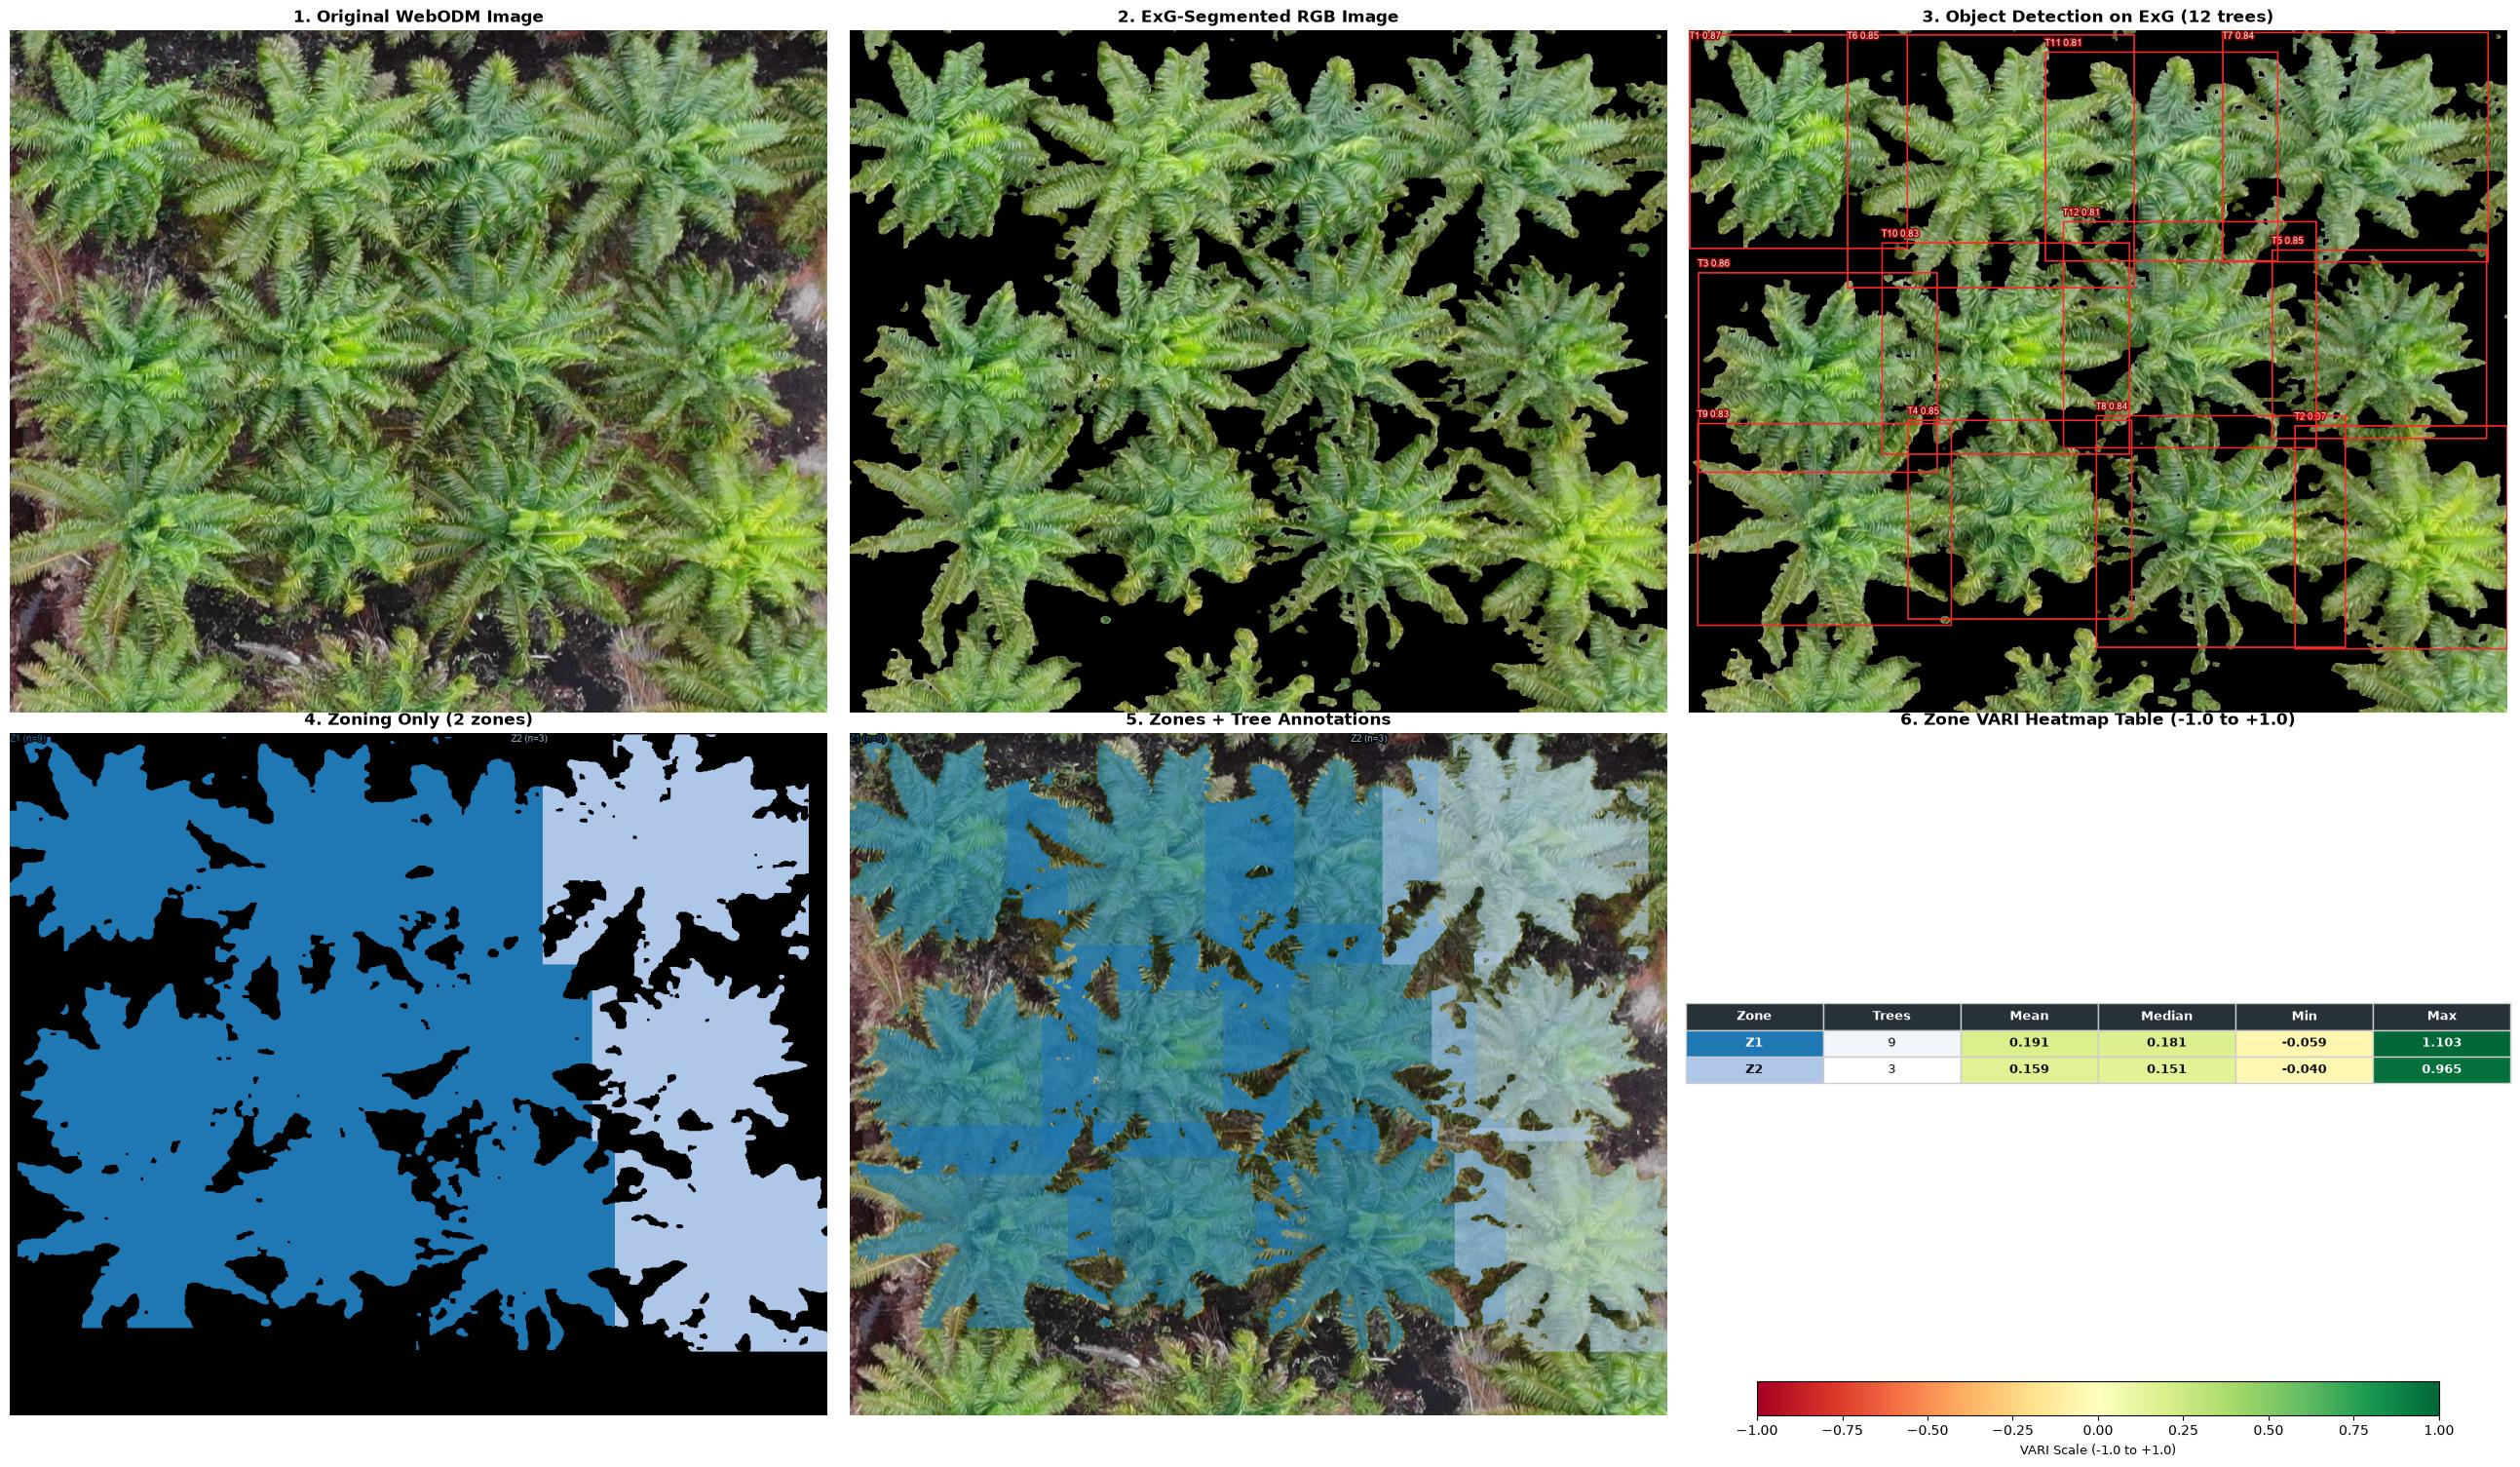

In [13]:
# From segmentation/final_flow/notebook.ipynb on master (97fbbf5); logic unchanged.
# Build and save the 2x3 visualization figure (5 images + 1 VARI Heatmap Table)
fig, axes = plt.subplots(2, 3, figsize=(26, 15))

axes[0][0].imshow(original_rgb)
axes[0][0].set_title("1. Original WebODM Image", fontsize=12, fontweight="bold")
axes[0][0].axis("off")

axes[0][1].imshow(segmented_rgb)
axes[0][1].set_title("2. ExG-Segmented RGB Image", fontsize=12, fontweight="bold")
axes[0][1].axis("off")

axes[0][2].imshow(coreml_on_exg_img)
axes[0][2].set_title(f"3. Object Detection on ExG ({len(trees)} trees)", fontsize=12, fontweight="bold")
axes[0][2].axis("off")

axes[1][0].imshow(zones_only_img)
axes[1][0].set_title(f"4. Zoning Only ({len(zones)} zones)", fontsize=12, fontweight="bold")
axes[1][0].axis("off")

axes[1][1].imshow(combined_annotated_img)
axes[1][1].set_title("5. Zones + Tree Annotations", fontsize=12, fontweight="bold")
axes[1][1].axis("off")

# 6th Panel: Zone VARI Heatmap Table (-1.0 to +1.0)
ax_table = axes[1][2]
ax_table.axis("off")
ax_table.set_title("6. Zone VARI Heatmap Table (-1.0 to +1.0)", fontsize=12, fontweight="bold")

if zone_json:
    cmap_vari = plt.colormaps["RdYlGn"]
    norm_vari = mcolors.Normalize(vmin=-1.0, vmax=1.0)
    col_labels = ["Zone", "Trees", "Mean", "Median", "Min", "Max"]
    heatmap_cols = {2, 3, 4, 5}

    cell_text, cell_colors, text_colors = [], [], []
    for r_idx, z in enumerate(zone_json):
        st = z.get("vari", {})
        vals = [st.get("mean_vari"), st.get("median_vari"), st.get("min_vari"), st.get("max_vari")]
        row_str = [
            f"Z{z['zone_id']}",
            str(z["tree_count"]),
            *[f"{v:.3f}" if (v is not None and np.isfinite(v)) else "N/A" for v in vals],
        ]
        raw_row = [None, None, *vals]
        base_bg = (0.95, 0.96, 0.98, 1.0) if r_idx % 2 == 0 else (1.0, 1.0, 1.0, 1.0)
        r_bg, r_fg = [], []
        for c_idx, v in enumerate(raw_row):
            if c_idx == 0:
                z_rgba = cmap_zones((z["zone_id"] - 1) % 20 / 20.0)
                r_bg.append(z_rgba)
                lum = 0.299 * z_rgba[0] + 0.587 * z_rgba[1] + 0.114 * z_rgba[2]
                r_fg.append("#111111" if lum > 0.52 else "#ffffff")
            elif c_idx in heatmap_cols and v is not None and np.isfinite(v):
                rgba = cmap_vari(norm_vari(float(np.clip(v, -1.0, 1.0))))
                r_bg.append(rgba)
                lum = 0.299 * rgba[0] + 0.587 * rgba[1] + 0.114 * rgba[2]
                r_fg.append("#111111" if lum > 0.52 else "#ffffff")
            else:
                r_bg.append(base_bg)
                r_fg.append("#111111")
        cell_text.append(row_str)
        cell_colors.append(r_bg)
        text_colors.append(r_fg)

    tbl = ax_table.table(
        cellText=cell_text,
        colLabels=col_labels,
        cellColours=cell_colors,
        cellLoc="center",
        loc="center",
    )
    tbl.auto_set_font_size(False)
    tbl.set_fontsize(9)
    tbl.scale(1.0, 1.35)

    for (r, c), cell in tbl.get_celld().items():
        cell.set_edgecolor("#cccccc")
        if r == 0:
            cell.set_facecolor("#263238")
            cell.get_text().set_color("white")
            cell.get_text().set_weight("bold")
        else:
            cell.get_text().set_color(text_colors[r - 1][c])
            if c in heatmap_cols or c == 0:
                cell.get_text().set_weight("bold")

    sm = cm.ScalarMappable(cmap=cmap_vari, norm=norm_vari)
    sm.set_array([])
    cbar = fig.colorbar(sm, ax=ax_table, orientation="horizontal", fraction=0.05, pad=0.04)
    cbar.set_label("VARI Scale (-1.0 to +1.0)", fontsize=9)
    cbar.set_ticks(np.linspace(-1.0, 1.0, 9))

plt.tight_layout()
fig.savefig(OUTPUT_PIPELINE_PLOT, dpi=200, bbox_inches="tight")

print("\n6/6: Outputs written:")
print(f"  1. ExG mask:                 {OUTPUT_EXG_MASK}")
print(f"  2. ExG-segmented RGB:        {OUTPUT_EXG_SEGMENTED}")
print(f"  3. Detections on ExG image:  {OUTPUT_COREML_ANNOTATED}")
print(f"  4. Zones only (on original): {OUTPUT_ZONE_ANNOTATED}")
print(f"  5. Zones + trees (original): {OUTPUT_ANNOTATED_IMAGE}")
print(f"  6. 6-Panel comparison plot:  {OUTPUT_PIPELINE_PLOT}")
print(f"  7. JSON output:              {OUTPUT_JSON}")
print(f"  8. Zone VARI CSV:            {OUTPUT_ZONE_CSV}")

plt.show()

# Part B: VARI confidence (the rule from "Status Cuaca Krops")

VARI also moves for reasons that have nothing to do with nutrients:
- **The flight.** A low sun casts long shadows into the crowns. Broken cloud changes the light from one photo to the
  next. Leaves still wet from rain look darker.
- **Water.** A palm short of water can turn pale like a palm short of nutrients (L5: P30 under 60 mm).

Each of these becomes a factor from 0 to 1, and the confidence is their product:

> **confidence = sun × cloud × wet leaves × water**, labelled *tinggi* (≥ 0.8), *sedang* (≥ 0.5) or *rendah*
> (below that).

An input that isn't known never scores 1, and the result is then marked `final: false`.

The code in this part is copied from `weather/` on `feat/weather-vari-confidence`, commit 6175bca. Module prefixes such
as `rules.` and `job.` are removed, and only what one scan needs is kept. If `weather/l6_vari_confidence.py` changes,
this copy has to change with it.

## B1. The rule's numbers
**What:**
- The lines and factor values from `l6_vari_confidence.py`.
- The two decided lines it reuses from `krops_rules.py`: P30 under 60 mm, and heavy rain over 25 mm.
- The P30 rule's settings, and the weather sources' grid sizes and URL.
- A table of every factor value.

**Why:**
- A team decision or a calibration would change these numbers, so they sit together at the top.
- Every value marked `GUESS` has no source yet.
- The table is built from the constants, so it can't disagree with the code.

In [14]:
# Copied from weather/l6_vari_confidence.py, weather/krops_rules.py, weather/nasa_power_job.py, weather/solar.py on feat/weather-vari-confidence (6175bca); keep in sync.

# The confidence rule (l6_vari_confidence.py)
SCHEMA_VERSION = 1
TZ = ZoneInfo("Asia/Jakarta")
HOUR = timedelta(hours=1)

SUN_BANDS = ((45.0, 1.0, "high"), (30.0, 0.85, "medium"), (15.0, 0.6, "low"))  # GUESS – no source yet: lowest sun °
SUN_VERY_LOW = 0.3            # GUESS – no source yet: sun under the last band
SUN_UNKNOWN = 0.6             # GUESS – no source yet: flight time or place unknown
CLOUD_CLEAR_MAX = 0.2         # GUESS – no source yet: cloud cover up to this is a clear sky
CLOUD_OVERCAST_MIN = 0.8      # GUESS – no source yet: from this on, overcast
CLOUD_FACTOR = {"clear": 1.0, "broken": 0.7, "overcast": 0.85, "unknown": 0.8}  # GUESS – no source yet
CLEARNESS_CLEAR_MIN = 0.7     # GUESS – no source yet: NASA POWER ALLSKY ÷ FAO-56 clear sky for a clear day
CLEARNESS_OVERCAST_MAX = 0.35 # GUESS – no source yet: … and for an overcast one
WET_HOURS = 6                 # GUESS – no source yet: rain this close before the flight can leave the leaves wet
WET_RAIN_MM = 0.5             # GUESS – no source yet
WET_FACTOR = {"dry": 1.0, "rain_before": 0.7, "heavy_day_before": 0.85, "unknown": 0.85}  # GUESS – no source yet
WATER_FACTOR = {"ok": 1.0, "fallback": 0.9, "water_stress": 0.6, "unknown": 0.75}  # GUESS – no source yet; how far L6
                                                                                   # lowers water_stress is a team value
LABELS = ((0.8, "tinggi"), (0.5, "sedang"))  # GUESS – no source yet; anything lower is "rendah"

# Decided L5 and L8 lines, and the P30 rule's settings (krops_rules.py)
P30_THRESHOLD_MM = 60.0     # L5: water_stress when P30 is under this (proposal)
P30_WINDOW_DAYS = 30
P30_MAX_AGE_DAYS = 7        # a window ending earlier than this many days ago is too old (proposed)
P30_SOURCE_ORDER = ("weatherkit-history", "nasa-power")  # proposed; on 9 Oct NASA POWER came first

SUSPECT_RATIO = 3.0         # NASA POWER monthly check (proposed)
SUSPECT_MIN_DAYS = 5        # GUESS – no source yet: a month with fewer NASA POWER days can't be judged (unchecked);
                            # at 5 or less, last month's checked window stays recent enough while a new month fills in
NORMAL_PERIOD = (1991, 2020)
HEAVY_RAIN_MM = 25.0        # L8 Stage B: a day over this is heavy (proposal)

# Weather sources (nasa_power_job.py)
POWER_URL = "https://power.larc.nasa.gov/api/temporal/daily/point"
RAIN = "PRECTOTCORR"
SUN = "ALLSKY_SFC_SW_DWN"  # logged only (design doc), no rule reads it
GRID_LAT, GRID_LON = 0.5, 0.625  # NASA POWER rain grid (MERRA-2)
WK_AREA = 0.1                    # WeatherKit P30 area, about 11 km: WeatherKit resolves about 10 km
RECENT_LOOKBACK_DAYS = 45        # recent rain starts on the 1st of the month holding today − 45: last month is whole

# Sun (solar.py)
SOLAR_CONSTANT_MJ_MIN = 0.0820          # Gsc, MJ m-2 min-1 (FAO-56 eq. 21)


factors = pd.DataFrame(
    [("sun", f"lowest elevation ≥ {floor:g}°", value) for floor, value, _ in SUN_BANDS]
    + [("sun", f"under {SUN_BANDS[-1][0]:g}°", SUN_VERY_LOW), ("sun", "unknown", SUN_UNKNOWN)]
    + [("cloud", f"{name} (clear ≤ {CLOUD_CLEAR_MAX:g}, overcast ≥ {CLOUD_OVERCAST_MIN:g})", value)
       for name, value in CLOUD_FACTOR.items()]
    + [("wet leaves", {"dry": "dry", "rain_before": f"≥ {WET_RAIN_MM:g} mm in {WET_HOURS} h before",
                       "heavy_day_before": f"> {HEAVY_RAIN_MM:g} mm in 24 h before (decided line)",
                       "unknown": "unknown"}[name], value) for name, value in WET_FACTOR.items()]
    + [("water (L5)", {"ok": "not stressed, WeatherKit", "fallback": "not stressed, NASA POWER fallback",
                       "water_stress": f"P30 under {P30_THRESHOLD_MM:g} mm", "unknown": "unknown"}[name], value)
       for name, value in WATER_FACTOR.items()],
    columns=["input", "when", "factor"]).set_index(["input", "when"])
display(factors)
print("Labels: " + " · ".join(f"{name} ≥ {floor}" for floor, name in LABELS) + " · otherwise rendah")

factor
input      when                                          
sun        lowest elevation ≥ 45°                    1.00
           lowest elevation ≥ 30°                    0.85
           lowest elevation ≥ 15°                    0.60
           under 15°                                 0.30
           unknown                                   0.60
cloud      clear (clear ≤ 0.2, overcast ≥ 0.8)       1.00
           broken (clear ≤ 0.2, overcast ≥ 0.8)      0.70
           overcast (clear ≤ 0.2, overcast ≥ 0.8)    0.85
           unknown (clear ≤ 0.2, overcast ≥ 0.8)     0.80
wet leaves dry                                       1.00
           ≥ 0.5 mm in 6 h before                    0.70
           > 25 mm in 24 h before (decided line)     0.85
           unknown                                   0.85
water (L5) not stressed, WeatherKit                  1.00
           not stressed, NASA POWER fallback         0.90
           P30 under 60 mm                           0.60
           unknown                                   0.75

Labels: tinggi ≥ 0.8 · sedang ≥ 0.5 · otherwise rendah


## B2. The rule: inputs → factors → confidence
**What:** turns what is known about the flight into factors, then combines them:
- **Sun:** the lowest sun elevation during the flight, scored by band.
- **Cloud:** the mean cloud cover over the flight, classed as clear, broken or overcast. When only NASA POWER is
  available, the class comes from its clearness for the day instead.
- **Wet leaves:** rain in the 6 hours and the 24 hours before take-off.
- **Water:** the L5 P30 record on the scan day.

`vari_confidence` multiplies the factors, adds the label, and writes an Indonesian reason for each factor under 1.

**Why:** these are pure functions, with no network and no files. The same inputs always give the same result, and
every number can be checked by hand.

In [15]:
# Copied from weather/l6_vari_confidence.py on feat/weather-vari-confidence (6175bca); keep in sync.
def sun_factor(elevation_deg):
    """(factor, class) for the lowest sun elevation during the flight."""
    if elevation_deg is None:
        return SUN_UNKNOWN, "unknown"
    for floor, factor, name in SUN_BANDS:
        if elevation_deg >= floor:
            return factor, name
    return SUN_VERY_LOW, "very_low"


def cloud_class(cover):
    """'clear', 'broken' or 'overcast' from a cloud cover between 0 and 1; None if unknown."""
    if cover is None:
        return None
    if cover <= CLOUD_CLEAR_MAX:
        return "clear"
    return "overcast" if cover >= CLOUD_OVERCAST_MIN else "broken"


def clearness_class(clearness):
    """The same classes from a day's NASA POWER clearness (ALLSKY ÷ FAO-56 clear sky); None if unknown."""
    if clearness is None:
        return None
    if clearness >= CLEARNESS_CLEAR_MIN:
        return "clear"
    return "overcast" if clearness <= CLEARNESS_OVERCAST_MAX else "broken"


def wet_class(last_6h_mm, last_24h_mm):
    """Whether the leaves may still be wet at take-off. Rain that isn't known is never taken as no rain."""
    if last_6h_mm is not None and last_6h_mm >= WET_RAIN_MM:
        return "rain_before"
    if last_24h_mm is not None and last_24h_mm > HEAVY_RAIN_MM:  # strictly over, as in L8 Stage B
        return "heavy_day_before"
    if last_6h_mm is not None and last_24h_mm is not None:
        return "dry"
    return "unknown"


def water_class(p30):
    """From the L5 P30 record on the scan date: 'ok', 'fallback' (NASA POWER), 'water_stress' or 'unknown'."""
    if not p30 or p30.get("water_stress") is None:
        return "unknown"
    if p30["water_stress"]:
        return "water_stress"
    return "ok" if p30.get("p30_quality") == "ok" else "fallback"


def label_for(confidence):
    for floor, name in LABELS:
        if confidence >= floor:
            return name
    return "rendah"


def _num(x, digits=0):
    """A number the Indonesian way: decimal comma."""
    return f"{x:.{digits}f}".replace(".", ",")


def _reason(name, f):
    """The code and an Indonesian sentence for a factor under 1, built only from what is known."""
    c = f["class"]
    if c == "unknown":
        text = {"sun": "Waktu atau lokasi terbang tidak diketahui.",
                "cloud": "Tutupan awan saat terbang tidak diketahui.",
                "wet": "Hujan sebelum terbang tidak diketahui.",
                "water": "P30 tidak diketahui pada tanggal scan."}[name]
    elif name == "sun":
        text = f"Matahari {_num(f['elevation_deg'])}° di atas cakrawala saat terbang: bayangan memanjang."
    elif name == "cloud":
        cover = f" ({f['cover']:.0%})" if f.get("cover") is not None else " (menurut NASA POWER, sepanjang hari)"
        text = (f"Awan sebagian{cover} saat terbang: terang berganti antar-foto." if c == "broken" else
                f"Langit mendung{cover} saat terbang: cahaya rata tapi redup.")
    elif name == "wet":
        text = (f"Hujan {_num(f['last_6h_mm'], 1)} mm dalam {WET_HOURS} jam sebelum terbang: daun mungkin basah."
                if c == "rain_before" else f"Hujan lebat {_num(f['last_24h_mm'])} mm dalam 24 jam sebelum terbang.")
    elif c == "water_stress":
        text = (f"P30 {_num(f['p30']['p30_mm'])} mm, di bawah {_num(P30_THRESHOLD_MM)} mm: tajuk bisa pucat karena "
                "kering, bukan karena hara.")
    else:
        text = "P30 dari NASA POWER (cadangan), sumber yang cenderung terlalu basah."
    return {"code": f"{name}_{c}", "factor": f["value"], "text": text}


def vari_confidence(sun_elevation_deg, cloud, rain, p30):
    """The confidence for one scan from what is known about its flight and its water.

    cloud = {"cover", "class", "source"[, "clearness"]}, rain = {"last_6h_mm", "last_24h_mm", "source"}, p30 = the L5
    record from choose_p30 (or None). Returns the confidence, its label, both components, every factor with its input
    and source, the reasons for each factor under 1, and `final`: False while any input is still unknown.
    """
    sun_value, sun_cls = sun_factor(sun_elevation_deg)
    cloud_cls = cloud.get("class") or "unknown"
    wet_cls = wet_class(rain.get("last_6h_mm"), rain.get("last_24h_mm"))
    water_cls = water_class(p30)
    factors = {
        "sun": {"value": sun_value, "class": sun_cls, "elevation_deg": sun_elevation_deg},
        "cloud": {"value": CLOUD_FACTOR[cloud_cls], "class": cloud_cls} | {k: v for k, v in cloud.items() if k != "class"},
        "wet": {"value": WET_FACTOR[wet_cls], "class": wet_cls} | rain,
        "water": {"value": WATER_FACTOR[water_cls], "class": water_cls, "p30": p30},
    }
    measurement = round(factors["sun"]["value"] * factors["cloud"]["value"] * factors["wet"]["value"], 3)
    confidence = round(measurement * factors["water"]["value"], 3)
    return {
        "confidence": confidence,
        "label": label_for(confidence),
        "final": all(f["class"] != "unknown" for f in factors.values()),
        "components": {"pengukuran": measurement, "air": factors["water"]["value"]},
        "factors": factors,
        "reasons": [_reason(name, f) for name, f in factors.items() if f["value"] < 1],
    }

## B3. Where the sun was
**What:**
- `solar_position` is NOAA's solar calculator. It gives the sun's elevation seen from the plot at a UTC time,
  including refraction.
- `lowest_sun` takes the lowest elevation at the flight's start, middle and end.
- The FAO-56 daily radiation functions give a clear-sky reference. They are only used when NASA POWER has to stand in
  for cloud.

**Why:**
- A low sun casts long shadows into the crowns.
- The sun is the one factor a farmer controls, by picking the hour.
- This is plain maths, with no network.

In [16]:
# Copied from weather/solar.py, weather/l6_vari_confidence.py on feat/weather-vari-confidence (6175bca); keep in sync.
def _sin(deg):
    return math.sin(math.radians(deg))


def _cos(deg):
    return math.cos(math.radians(deg))


def _tan(deg):
    return math.tan(math.radians(deg))


def _clamp(x):
    return min(1.0, max(-1.0, x))  # keeps acos/asin defined when rounding lands just outside [-1, 1]


def julian_day(when_utc):
    """Julian day of a timezone-aware datetime, from its Unix time (Swift: date.timeIntervalSince1970)."""
    if when_utc.tzinfo is None:
        raise ValueError("when_utc must be timezone-aware")
    return when_utc.timestamp() / 86400.0 + 2440587.5


def _refraction_deg(elevation):
    """Atmospheric refraction to add to the true elevation (NOAA's piecewise fit)."""
    if elevation > 85.0:
        return 0.0
    if elevation > 5.0:
        t = _tan(elevation)
        arcsec = 58.1 / t - 0.07 / t ** 3 + 0.000086 / t ** 5
    elif elevation > -0.575:
        e = elevation
        arcsec = 1735.0 + e * (-518.2 + e * (103.4 + e * (-12.79 + e * 0.711)))
    else:
        arcsec = -20.772 / _tan(elevation)
    return arcsec / 3600.0


def solar_position(lat, lon, when_utc):
    """Where the sun is, seen from (lat, lon) at when_utc.

    zenith_deg and elevation_deg include atmospheric refraction (where the sun appears, what a camera sees);
    true_zenith_deg leaves it out. azimuth_deg runs clockwise from north. NOAA quotes about one arc-minute of
    accuracy for 1800–2100 while the sun is clear of the horizon.
    """
    jc = (julian_day(when_utc) - 2451545.0) / 36525.0  # Julian centuries since J2000
    minutes_utc = (when_utc.timestamp() % 86400.0) / 60.0  # Swift: use a remainder that stays positive

    mean_long = (280.46646 + jc * (36000.76983 + jc * 0.0003032)) % 360.0
    mean_anom = 357.52911 + jc * (35999.05029 - 0.0001537 * jc)
    ecc = 0.016708634 - jc * (0.000042037 + 0.0000001267 * jc)
    centre = (_sin(mean_anom) * (1.914602 - jc * (0.004817 + 0.000014 * jc))
              + _sin(2 * mean_anom) * (0.019993 - 0.000101 * jc)
              + _sin(3 * mean_anom) * 0.000289)
    omega = 125.04 - 1934.136 * jc
    app_long = mean_long + centre - 0.00569 - 0.00478 * _sin(omega)
    mean_obliq = 23.0 + (26.0 + (21.448 - jc * (46.815 + jc * (0.00059 - jc * 0.001813))) / 60.0) / 60.0
    obliq = mean_obliq + 0.00256 * _cos(omega)
    decl = math.degrees(math.asin(_clamp(_sin(obliq) * _sin(app_long))))

    y = _tan(obliq / 2.0) ** 2
    eq_time_min = 4.0 * math.degrees(
        y * _sin(2 * mean_long) - 2 * ecc * _sin(mean_anom) + 4 * ecc * y * _sin(mean_anom) * _cos(2 * mean_long)
        - 0.5 * y * y * _sin(4 * mean_long) - 1.25 * ecc * ecc * _sin(2 * mean_anom))
    true_solar_min = (minutes_utc + eq_time_min + 4.0 * lon) % 1440.0  # in [0, 1440)
    hour_angle = true_solar_min / 4.0 - 180.0

    cos_zen = _clamp(_sin(lat) * _sin(decl) + _cos(lat) * _cos(decl) * _cos(hour_angle))
    true_zenith = math.degrees(math.acos(cos_zen))
    elevation = 90.0 - true_zenith + _refraction_deg(90.0 - true_zenith)

    denom = _cos(lat) * _sin(true_zenith)
    if abs(denom) < 1e-12:
        azimuth = 180.0  # sun straight overhead (or observer at a pole): azimuth is undefined
    else:
        a = math.degrees(math.acos(_clamp((_sin(lat) * cos_zen - _sin(decl)) / denom)))
        azimuth = (a + 180.0) % 360.0 if hour_angle > 0 else (540.0 - a) % 360.0
    return {
        "zenith_deg": 90.0 - elevation,
        "elevation_deg": elevation,
        "true_zenith_deg": true_zenith,
        "azimuth_deg": azimuth,
    }


def day_of_year(day):
    """1 for 1 January … 365 or 366 (FAO-56's J)."""
    return day.timetuple().tm_yday


def extraterrestrial_daily(lat, doy):
    """Ra, MJ m-2 day-1: the day's sunlight on a level surface at the top of the atmosphere (FAO-56 eqs. 21–25)."""
    phi = math.radians(lat)
    b = 2.0 * math.pi * doy / 365.0
    dr = 1.0 + 0.033 * math.cos(b)                 # inverse relative Earth–Sun distance (eq. 23)
    decl = 0.409 * math.sin(b - 1.39)              # solar declination, radians (eq. 24)
    ws = math.acos(_clamp(-math.tan(phi) * math.tan(decl)))  # sunset hour angle (eq. 25); clamped for polar day/night
    return (24.0 * 60.0 / math.pi * SOLAR_CONSTANT_MJ_MIN * dr
            * (ws * math.sin(phi) * math.sin(decl) + math.cos(phi) * math.cos(decl) * math.sin(ws)))


def clear_sky_fao56(ra, elevation_m=0.0):
    """Rso, MJ m-2 day-1: clear-sky sunlight at the surface from Ra and the site's elevation (FAO-56 eq. 37)."""
    return (0.75 + 2e-5 * elevation_m) * ra


def lowest_sun(lat, lon, start, end):
    """The lowest sun elevation (degrees) at the start, middle and end of the flight."""
    mid = start + (end - start) / 2
    return round(min(solar_position(lat, lon, t)["elevation_deg"] for t in (start, mid, end)), 1)

## B4. Weather sources: NASA POWER and WeatherKit
**What:**
- `fetch_nasa_power` gets daily values from NASA POWER, which is public and needs no key, and retries on errors. It is
  asked at the centre of the plot's MERRA-2 grid cell (`grid_cell`).
- `WeatherKit` is the client for Apple's weather API. It signs a token with the keys from `.env`, then:
  - `hourly` gets past hours (cloud and rain around the flight)
  - `daily` gets day parts
  - `history` gets daily rain, 10 days per request, and asks once more when Apple leaves out a day
- `daily_from_pairs`: a date or hour given twice counts once when the values agree, and as missing when they don't.

**Why:** WeatherKit is the first source for every weather input, and NASA POWER is the fallback. A missing value is
never taken as 0 mm or a clear sky.

In [17]:
# Copied from weather/nasa_power_job.py, weather/krops_rules.py on feat/weather-vari-confidence (6175bca); keep in sync.
def _snap(value, step, offset=0.0):
    return math.floor((value + offset) / step + 0.5) * step - offset  # round half up, the same in Swift


def _place_id(lat, lon):
    return f"{'n' if lat >= 0 else 's'}{abs(lat):.3f}_{'e' if lon >= 0 else 'w'}{abs(lon):.4f}"


def grid_cell(lat, lon):
    """The rain grid cell holding a point: its centre (where we query NASA POWER) and a stable id."""
    clat, clon = _snap(lat, GRID_LAT), _snap(lon, GRID_LON, 180.0)
    return {"id": _place_id(clat, clon), "lat": round(clat, 4), "lon": round(clon, 4)}


def weatherkit_area(lat, lon):
    """The ~11 km box (0.1°) whose centre we query WeatherKit at for P30; plots in one box share it."""
    clat, clon = _snap(lat, WK_AREA), _snap(lon, WK_AREA)
    return {"id": _place_id(clat, clon), "lat": round(clat, 4), "lon": round(clon, 4)}


def _spans(days):
    """Runs of consecutive dates: [d1, d2, d3, d7] → [(d1, d3), (d7, d7)]."""
    spans = []
    for d in sorted(days):
        if spans and d == spans[-1][1] + timedelta(days=1):
            spans[-1] = (spans[-1][0], d)
        else:
            spans.append((d, d))
    return spans


def fetch_nasa_power(lat, lon, start, end, params, session, retries=3):
    """Daily values {param: {date: value or None}}, units and sources. Retries on timeouts, 429 and 5xx."""
    query = {"parameters": ",".join(params), "community": "AG", "latitude": lat, "longitude": lon,
             "start": f"{start:%Y%m%d}", "end": f"{end:%Y%m%d}", "format": "JSON"}
    for attempt in range(retries):
        try:
            r = session.get(POWER_URL, params=query, timeout=180)
            if r.status_code == 429 or r.status_code >= 500:
                raise requests.HTTPError(f"NASA POWER answered {r.status_code}", response=r)
            r.raise_for_status()
            payload = r.json()
            break
        except (requests.RequestException, ValueError) as error:
            if attempt == retries - 1:
                raise
            wait = 15 * 2 ** attempt
            log.warning("NASA POWER request failed (%s); retrying in %ss", error, wait)
            time.sleep(wait)

    fill = payload["header"]["fill_value"]
    values = {param: {datetime.strptime(day, "%Y%m%d").date(): (None if v == fill else float(v))
                      for day, v in series.items()}
              for param, series in payload["properties"]["parameter"].items()}
    units = {k: v["units"] for k, v in payload["parameters"].items()}
    if RAIN in params and units.get(RAIN) != "mm/day":  # the cloud fallback asks for sunlight alone
        raise ValueError(f"unexpected rain unit from NASA POWER: {units.get(RAIN)}")
    return values, units, payload["header"].get("sources", [])


def daily_from_pairs(pairs):
    """{date: mm or None} from raw (date, mm) pairs, one entry per date.

    A date given more than once keeps its value when every value agrees, and becomes missing (None) when they
    disagree: there is no telling which one is right. A None next to a value isn't a disagreement.
    """
    values = {}
    for d, v in pairs:
        values.setdefault(d, set())
        if v is not None:
            values[d].add(float(v))
    return {d: (next(iter(v)) if len(v) == 1 else None) for d, v in sorted(values.items())}


class WeatherKit:
    """Minimal WeatherKit REST client: daily values only. Server-side only, the .p8 key never ships in the app."""

    BASE = "https://weatherkit.apple.com"
    MAX_DAYS = 10  # days per daily request (Apple's limit)
    retries = 0    # re-requests for short replies this run

    def __init__(self, team_id, key_id, service_id, key_path, session, tz):
        self.team_id, self.key_id, self.service_id = team_id, key_id, service_id
        self.key = Path(key_path).expanduser().read_text()
        self.session, self.tz = session, tz
        self.calls = 0

    @classmethod
    def from_env(cls, session, tz):
        names = ["WK_TEAM_ID", "WK_KEY_ID", "WK_SERVICE_ID", "WK_KEY_PATH"]
        values = [os.getenv(n) for n in names]
        if not all(values) or not Path(values[3]).expanduser().is_file():
            return None
        return cls(*values, session=session, tz=tz)

    def _token(self):
        import jwt  # only needed when WeatherKit is configured

        now = int(time.time())
        return jwt.encode({"iss": self.team_id, "iat": now, "exp": now + 3600, "sub": self.service_id}, self.key,
                          algorithm="ES256", headers={"kid": self.key_id, "id": f"{self.team_id}.{self.service_id}"})

    def _utc(self, day):
        return datetime.combine(day, datetime.min.time(), self.tz).astimezone(timezone.utc).strftime("%Y-%m-%dT%H:%M:%SZ")

    def _get(self, lat, lon, params):
        r = self.session.get(f"{self.BASE}/api/v1/weather/en/{lat}/{lon}", params=params,
                             headers={"Authorization": f"Bearer {self._token()}"}, timeout=30)
        self.calls += 1
        r.raise_for_status()
        return r.json()

    def daily(self, lat, lon, start=None, end=None):
        params = {"dataSets": "forecastDaily", "timezone": str(self.tz)}
        if start:
            params |= {"dailyStart": self._utc(start), "dailyEnd": self._utc(end + timedelta(days=1))}
        return self._get(lat, lon, params)

    def hourly(self, lat, lon, start, end):
        """Past hourly values for the hours starting in [start, end) (aware datetimes, one request of at most 240 hours:
        Apple answers 400 to a longer range).

        Returns {hour start (UTC): {"cloud_cover", "rain_mm", "daylight", "condition"}}. An hour returned twice keeps a
        value only if the copies agree (daily_from_pairs), as daily rain does.
        """
        stamp = "%Y-%m-%dT%H:%M:%SZ"
        reply = self._get(lat, lon, {"dataSets": "forecastHourly", "timezone": str(self.tz),
                                     "hourlyStart": start.astimezone(timezone.utc).strftime(stamp),
                                     "hourlyEnd": end.astimezone(timezone.utc).strftime(stamp)})
        hours = []
        for h in reply.get("forecastHourly", {}).get("hours", []):
            t = datetime.fromisoformat(h["forecastStart"].replace("Z", "+00:00"))
            if start <= t < end:
                hours.append((t, h))
        cloud = daily_from_pairs((t, h.get("cloudCover")) for t, h in hours)
        rain = daily_from_pairs((t, h.get("precipitationAmount")) for t, h in hours)
        first = {}
        for t, h in hours:
            first.setdefault(t, h)
        return {t: {"cloud_cover": cloud[t], "rain_mm": rain[t], "daylight": first[t].get("daylight"),
                    "condition": first[t].get("conditionCode")} for t in sorted(first)}

    def _days(self, lat, lon, first, last, start, end):
        """(local date, mm) for the days one request for first–last returns, kept when they fall inside start–end."""
        got = []
        for d in self.daily(lat, lon, first, last).get("forecastDaily", {}).get("days", []):
            local = datetime.fromisoformat(d["forecastStart"].replace("Z", "+00:00")).astimezone(self.tz).date()
            if start <= local <= end:
                got.append((local, d.get("precipitationAmount")))
        return got

    def _retry(self, lat, lon, first, last, start, end, before):
        """One more request for the missing days first–last, with the gap in the middle of the range.

        Apple has dropped the last day of a request (1 Jun 2023, every time) yet returns it from a range where it isn't
        the last day. Returns what the retry gave inside start–end; `before` (the replies so far) is only for the log.
        """
        spare = self.MAX_DAYS - ((last - first).days + 1)
        ask_first, ask_last = first - timedelta(days=spare // 2), last + timedelta(days=spare - spare // 2)
        self.retries += 1
        try:
            got = self._days(lat, lon, ask_first, ask_last, start, end)
        except Exception:
            log.warning("WeatherKit retry %s to %s failed; %s to %s stay missing", ask_first, ask_last, first, last,
                        exc_info=True)
            return []
        wanted = {first + timedelta(days=i) for i in range((last - first).days + 1)}
        recovered = sorted({d for d, v in got if d in wanted and v is not None})
        earlier = dict(before)
        disagree = sorted({d for d, v in got if d in earlier and earlier[d] != v})
        log.warning("WeatherKit retry %s to %s for %s to %s: recovered %d of %d day(s)%s%s", ask_first, ask_last, first,
                    last, len(recovered), len(wanted), f" ({', '.join(d.isoformat() for d in recovered)})" if recovered else "",
                    f"; {len(disagree)} day(s) disagree with an earlier reply and count as missing" if disagree else "")
        return got

    def history(self, lat, lon, start, end):
        """{date: mm or None} from past daily values, 10 days per request (Apple's limit).

        A request that comes back short is logged and retried once per gap (see _retry). Everything WeatherKit returns
        goes through daily_from_pairs: a date given twice counts once if the values agree, and as missing if not.
        """
        pairs, day = [], start
        while day <= end:
            stop = min(day + timedelta(days=self.MAX_DAYS - 1), end)
            got = self._days(lat, lon, day, stop, start, end)
            asked = [day + timedelta(days=i) for i in range((stop - day).days + 1)]
            absent = sorted(set(asked) - {local for local, _ in got})
            if absent:
                log.warning("WeatherKit gave %d of %d days for %s, %s (%s to %s); missing %s", len(asked) - len(absent),
                            len(asked), lat, lon, day, stop, ", ".join(d.isoformat() for d in absent))
            for first, last in _spans(absent):
                got += self._retry(lat, lon, first, last, start, end, before=got)
            pairs += got
            day = stop + timedelta(days=1)
        return daily_from_pairs(pairs)

## B5. Weather during and before the flight
**What:** finds the cloud and the rain for the flight, one source per input:
- **Cloud.** It comes from the first of these that has a value:
  1. the mean over the flight hours from WeatherKit hourly
  2. WeatherKit's daytime cloud (07:00–19:00)
  3. NASA POWER's clearness for the day
- **Rain before take-off.** From WeatherKit hourly, rain in the last 6 h and 24 h, summed only when every hour is there.
  The fallback is WeatherKit's day parts, which only give 24 h.

**Why:** cloud and wet leaves change the colour the camera records. An hour with no data makes the sum unknown, never
0 mm.

In [18]:
# Copied from weather/l6_vari_confidence.py on feat/weather-vari-confidence (6175bca); keep in sync.
def flight_cloud(hours, start, end):
    """Mean cloud cover over the hours the flight overlaps; None if none of them has a value."""
    covers = [h["cloud_cover"] for t, h in hours.items()
              if t < end and t + HOUR > start and h["cloud_cover"] is not None]
    return round(sum(covers) / len(covers), 3) if covers else None


def rain_before(hours, start, span_hours):
    """Rain in the span_hours before take-off, over every hour that overlaps that span; None if any hour is missing."""
    t = (start - timedelta(hours=span_hours)).astimezone(timezone.utc).replace(minute=0, second=0, microsecond=0)
    total = 0.0
    while t < start:
        h = hours.get(t)
        if h is None or h["rain_mm"] is None:
            return None
        total += h["rain_mm"]
        t += HOUR
    return round(total, 2)


def dayparts(reply, flight_day, tz=TZ):
    """(cloud cover 07:00–19:00 on the flight day, rain from 07:00 the day before to 07:00 the flight day).

    From WeatherKit's daily day parts; either is None when the reply lacks it.
    """
    days = {}
    for d in reply.get("forecastDaily", {}).get("days", []):
        days[datetime.fromisoformat(d["forecastStart"].replace("Z", "+00:00")).astimezone(tz).date()] = d
    today, before = days.get(flight_day) or {}, days.get(flight_day - timedelta(days=1)) or {}
    cover = (today.get("daytimeForecast") or {}).get("cloudCover")
    parts = [(before.get("daytimeForecast") or {}).get("precipitationAmount"),
             (before.get("overnightForecast") or {}).get("precipitationAmount")]
    return cover, None if any(p is None for p in parts) else round(sum(parts), 2)


def nasa_clearness(allsky, lat, day):
    """A day's ALLSKY_SFC_SW_DWN over the FAO-56 clear-sky sunlight for that latitude and day; None if unknown."""
    if allsky is None:
        return None
    clear = clear_sky_fao56(extraterrestrial_daily(lat, day_of_year(day)))
    return round(allsky / clear, 3) if clear > 0 else None


def flight_conditions(lat, lon, start, end, *, weatherkit=None, nasa_fetch=fetch_nasa_power, session=None, tz=TZ):
    """Cloud at the flight and rain before it, one source per input.

    WeatherKit hourly first; then WeatherKit's daily day parts; for cloud only, NASA POWER's clearness for the day.
    """
    cloud = {"cover": None, "class": None, "source": None}
    rain = {"last_6h_mm": None, "last_24h_mm": None, "source": None}
    day = start.astimezone(tz).date()
    if weatherkit:
        try:
            first = (start - timedelta(hours=24)).astimezone(timezone.utc).replace(minute=0, second=0, microsecond=0)
            hours = weatherkit.hourly(lat, lon, first, end + HOUR)  # from a whole hour: rain_before needs that hour
        except Exception:
            log.warning("WeatherKit hourly unavailable for %s; trying the daily day parts", day, exc_info=True)
            hours = {}
        if hours:
            cover = flight_cloud(hours, start, end)
            if cover is not None:
                cloud = {"cover": cover, "class": cloud_class(cover), "source": "weatherkit-hourly"}
            last_6h, last_24h = rain_before(hours, start, WET_HOURS), rain_before(hours, start, 24)
            if last_6h is not None or last_24h is not None:
                rain = {"last_6h_mm": last_6h, "last_24h_mm": last_24h, "source": "weatherkit-hourly"}
        if cloud["source"] is None or rain["source"] is None:
            try:
                cover, rain_24h = dayparts(weatherkit.daily(lat, lon, day - timedelta(days=1), day), day, tz)
            except Exception:
                log.warning("WeatherKit daily unavailable for %s", day, exc_info=True)
                cover, rain_24h = None, None
            if cloud["source"] is None and cover is not None:
                cloud = {"cover": cover, "class": cloud_class(cover), "source": "weatherkit-daytime"}
            if rain["source"] is None and rain_24h is not None:
                rain = {"last_6h_mm": None, "last_24h_mm": rain_24h, "source": "weatherkit-dayparts"}
    if cloud["source"] is None and nasa_fetch:
        cell = grid_cell(lat, lon)
        try:
            values, _, _ = nasa_fetch(cell["lat"], cell["lon"], day, day, (SUN,), session)
            clearness = nasa_clearness(values.get(SUN, {}).get(day), cell["lat"], day)
        except Exception:
            log.warning("NASA POWER unavailable for %s", day, exc_info=True)
            clearness = None
        if clearness is not None:
            cloud = {"cover": None, "class": clearness_class(clearness), "source": "nasa-power", "clearness": clearness}
    return cloud, rain

## B6. P30 on the scan day (the decided L5 rule)
**What:**
- P30 is the rain over the 30 days before the scan. All 30 days must be there, and the window must end no more than
  7 days before the scan.
- The first source is WeatherKit's daily history for the plot's area (about 11 km).
- NASA POWER is the fallback, but only after its monthly check. That check drops months that are implausibly wet
  against both the 1991–2020 normal and WeatherKit.
- The scan day itself is left out, because its rain isn't complete when the drone flies.

**Why:** with P30 under 60 mm, the palms may be pale from drought rather than from a lack of nutrients, so the water
factor lowers the confidence. The team decided this rule, and it is copied without changes.

In [19]:
# Copied from weather/krops_rules.py, weather/nasa_power_job.py, weather/l2_scan_rain.py, weather/l6_vari_confidence.py on feat/weather-vari-confidence (6175bca); keep in sync.
def _present(daily):
    return {d: float(v) for d, v in (daily or {}).items() if v is not None}


def missing_in_p30_window(daily):
    """Days missing inside the 30-day window ending on the latest day with a value (all 30 if no day has one).

    Missing days after that latest day aren't counted: they move the window back, and choose_p30's age limit
    decides whether it is still recent enough.
    """
    rain = _present(daily)
    if not rain:
        return P30_WINDOW_DAYS
    end = max(rain)
    return sum(1 for i in range(P30_WINDOW_DAYS) if end - timedelta(days=i) not in rain)


def compute_p30(daily, source):
    """P30 from one source: the 30 calendar days ending on the latest day with a value.

    All 30 days must be present; otherwise there is no P30 (None), rather than a sum of fewer days.
    """
    rain = _present(daily)
    if not rain:
        return None
    end = max(rain)
    window = [end - timedelta(days=i) for i in range(P30_WINDOW_DAYS - 1, -1, -1)]
    if any(d not in rain for d in window):
        return None
    p30_mm = round(sum(rain[d] for d in window), 1)
    return {
        "p30_mm": p30_mm,
        "p30_start_date": window[0],
        "p30_end_date": end,
        "p30_source": source,
        "water_stress": p30_mm < P30_THRESHOLD_MM,
    }


def choose_p30(sources, today, order=P30_SOURCE_ORDER, max_age_days=P30_MAX_AGE_DAYS):
    """The L5 data-contract record: the first source in `order` with a full window ending ≤ max_age_days ago.

    `sources` maps a source name to its daily rain (NASA POWER already filtered by `suspect_months`).
    p30_quality is "ok" for the first source in the order, "fallback" for a later one, "none" if none qualifies;
    with "none", p30_mm and water_stress are None (unknown), never a silent False. p30_missing_days gives, for every
    source in the order, the days missing inside its latest 30-day window (missing_in_p30_window), so a gap that
    sent P30 to the fallback shows in the record. A window is never completed from another source.
    """
    missing = {name: missing_in_p30_window(sources.get(name)) for name in order}
    for rank, name in enumerate(order):
        record = compute_p30(sources.get(name), name)
        if record and (today - record["p30_end_date"]).days <= max_age_days:
            return record | {"p30_quality": "ok" if rank == 0 else "fallback", "p30_missing_days": missing}
    return {"p30_mm": None, "p30_start_date": None, "p30_end_date": None,
            "p30_source": None, "water_stress": None, "p30_quality": "none", "p30_missing_days": missing}


def monthly_totals(daily):
    """{(year, month): total mm} over the days present."""
    totals = {}
    for d, v in _present(daily).items():
        totals[(d.year, d.month)] = totals.get((d.year, d.month), 0.0) + v
    return totals


def monthly_normals(daily, first=NORMAL_PERIOD[0], last=NORMAL_PERIOD[1]):
    """{calendar month: median monthly total} over the years first–last (default the 1991–2020 normal)."""
    by_month = {}
    for (y, m), total in monthly_totals(daily).items():
        if first <= y <= last:
            by_month.setdefault(m, []).append(total)
    return {m: median(v) for m, v in sorted(by_month.items())}


def suspect_months(nasa, normals, weatherkit=None, ratio=SUSPECT_RATIO):
    """NASA POWER months to drop: too wet against the normal AND against WeatherKit, by either of two tests.

    - Whole month (as before): the total over the days present is over ratio × the full-month normal, and over
      ratio × WeatherKit's total for the month (a month WeatherKit has no data for is judged on the normal alone).
    - Pro-rated, for a month still filling in: the same total against ratio × the normal scaled to the days NASA POWER
      has, and against ratio × WeatherKit's total on those same days (none of them → the normal alone).
    For a whole month the second test is the first one or stricter, so it only ever adds months: no window dropped
    before is kept now. Requiring WeatherKit too keeps a genuinely wet month, which WeatherKit also sees.
    """
    nasa_rain, wk_rain = _present(nasa), _present(weatherkit)
    wk_totals = monthly_totals(wk_rain)
    out = set()
    for (y, m), total in monthly_totals(nasa_rain).items():
        if total > ratio * normals[m] and ((y, m) not in wk_totals or total > ratio * wk_totals[(y, m)]):
            out.add((y, m))
            continue
        days = [d for d in nasa_rain if (d.year, d.month) == (y, m)]
        share = len(days) / calendar.monthrange(y, m)[1]
        wk_same = [wk_rain[d] for d in days if d in wk_rain]
        if total > ratio * normals[m] * share and (not wk_same or total > ratio * sum(wk_same)):
            out.add((y, m))
    return out


def unchecked_months(nasa, min_days=SUSPECT_MIN_DAYS):
    """NASA POWER months with too few days to judge: like suspect months, they can't serve as the fallback."""
    counts = {}
    for d in _present(nasa):
        counts[(d.year, d.month)] = counts.get((d.year, d.month), 0) + 1
    return {month for month, n in counts.items() if n < min_days}


def drop_months(daily, months):
    return {d: v for d, v in daily.items() if (d.year, d.month) not in months}


def _iso_record(record):
    """A P30 record with its dates as ISO strings (None stays None)."""
    if record is None:
        return None
    return record | {k: (record[k].isoformat() if record[k] else None) for k in ("p30_start_date", "p30_end_date")}


def build_recent(rain, normals_mm, weatherkit_rain=None):
    """Checked recent NASA POWER rain: suspect and unchecked months dropped, plus the NASA-only P30 from what is left.

    An unchecked month (fewer than SUSPECT_MIN_DAYS days) can't serve as the fallback until it can be judged.
    """
    normals = {int(m): v for m, v in normals_mm.items()}
    present = {d: v for d, v in rain.items() if v is not None}
    suspect = suspect_months(present, normals, weatherkit_rain)
    unchecked = unchecked_months(present) - suspect
    checked = drop_months(present, suspect | unchecked)
    return {
        "last_day": max(present).isoformat() if present else None,
        "checked_against": "normals and weatherkit" if weatherkit_rain else "normals",
        "suspect_months": [f"{y}-{m:02d}" for y, m in sorted(suspect)],
        "unchecked_months": [f"{y}-{m:02d}" for y, m in sorted(unchecked)],
        "rain_mm": {d.isoformat(): v for d, v in sorted(checked.items())},
        "nasa_p30": _iso_record(compute_p30(checked, "nasa-power")),
    }


def p30_at(sources, scan_date, order=P30_SOURCE_ORDER):
    """The L5 P30 record as it stood on scan_date: each source cut to the days before it, then choose_p30.

    The scan day itself is left out, as the job leaves out today: its rain isn't complete when the drone flies.
    """
    before = {name: {d: v for d, v in (daily or {}).items() if d < scan_date} for name, daily in sources.items()}
    return choose_p30(before, scan_date, order=order)


def scan_p30(lat, lon, scan_day, normals_mm, *, weatherkit=None, nasa_fetch=fetch_nasa_power, session=None):
    """The L5 P30 record as it stood on the scan day: WeatherKit for the plot's area first, checked NASA POWER next.

    The decided rule, unchanged (l2_scan_rain.p30_at → choose_p30). NASA POWER goes through the job's monthly
    check first, here against WeatherKit at the plot's area (the job uses the cell centre).
    """
    first = (scan_day - timedelta(days=RECENT_LOOKBACK_DAYS)).replace(day=1)
    last = scan_day - timedelta(days=1)
    area, cell = weatherkit_area(lat, lon), grid_cell(lat, lon)
    wk_rain = None
    if weatherkit:
        try:
            wk_rain = weatherkit.history(area["lat"], area["lon"], first, last)
        except Exception:
            log.warning("WeatherKit history unavailable before %s", scan_day, exc_info=True)
    checked = None
    if nasa_fetch:
        try:
            values, _, _ = nasa_fetch(cell["lat"], cell["lon"], first, last, (RAIN,), session)
            recent = build_recent(values[RAIN], normals_mm, wk_rain)
            checked = {date.fromisoformat(d): v for d, v in recent["rain_mm"].items()}
        except Exception:
            log.warning("NASA POWER unavailable before %s", scan_day, exc_info=True)
    return _iso_record(p30_at({"weatherkit-history": wk_rain, "nasa-power": checked}, scan_day))

## B7. The scan manifest
**What:** builds the record the phone would upload after a flight:
- the scan id and plot id
- the flight's start and end, in UTC
- a VARI summary from Part A:
  - `crowns`: the number of trees measured
  - `median`: the median of the per-tree median VARI
  - `iqr`: the spread of those per-tree medians (third quartile minus first)

**Why:** this is the rule's input on the backend (see `VARI_CONFIDENCE.md`). The rule itself reads only the times and
the plot. The VARI summary travels with the result, so a scan's VARI and its confidence stay together.

In [20]:
crown_medians = np.array([t["vari"]["median_vari"] for t in trees if t["vari"]["median_vari"] is not None])
q1, q2, q3 = np.percentile(crown_medians, [25, 50, 75])
scan = {
    "scan_id": SCAN_ID,
    "plot_id": PLOT_ID,
    "flight_start": FLIGHT_START_WIB.astimezone(timezone.utc).strftime("%Y-%m-%dT%H:%M:%SZ"),
    "flight_end": FLIGHT_END_WIB.astimezone(timezone.utc).strftime("%Y-%m-%dT%H:%M:%SZ"),
    "vari": {"crowns": int(crown_medians.size), "median": round(float(q2), 3), "iqr": round(float(q3 - q1), 3)},
}
print(json.dumps(scan, indent=1))

{
 "scan_id": "dji_15",
 "plot_id": "tanjung-pinang-trial",
 "flight_start": "2026-09-15T02:40:00Z",
 "flight_end": "2026-09-15T03:05:00Z",
 "vari": {
  "crowns": 12,
  "median": 0.172,
  "iqr": 0.016
 }
}


## B8. Connect to the weather sources
**What:**
- Opens WeatherKit with the keys from `.env`, or says that it is off.
- Loads the monthly rain normals (1991–2020, from NASA POWER) for the plot's grid cell. The P30 rule's monthly check
  needs them. They are fetched once, the way the backend's CLI does it, and cached in `outputs/climate_normals.json`.

**Why:**
- Without WeatherKit the rule still runs on NASA POWER alone. Rain before the flight is then unknown, so the result
  is marked not final.
- The normals take one large request (30 years of daily rain), so they are kept for next time.

In [21]:
session = requests.Session()
weatherkit = WeatherKit.from_env(session, TZ)
print("WeatherKit:", "on" if weatherkit else "off (no keys in .env): NASA POWER only, so the result won't be final")

NORMALS_FILE = OUT_DIR / "climate_normals.json"
cell = grid_cell(LAT, LON)
cached = json.loads(NORMALS_FILE.read_text()) if NORMALS_FILE.is_file() else {}
if cached.get("cell") == cell["id"]:
    normals_mm = cached["normals_mm"]
    print(f"Rain normals {NORMAL_PERIOD[0]}–{NORMAL_PERIOD[1]}: from {NORMALS_FILE}")
else:
    first, last = NORMAL_PERIOD
    values, _, _ = fetch_nasa_power(cell["lat"], cell["lon"], date(first, 1, 1), date(last, 12, 31), (RAIN,), session)
    normals_mm = {str(m): round(v, 1) for m, v in monthly_normals(values[RAIN], first, last).items()}
    if len(normals_mm) < 12:
        raise ValueError(f"NASA POWER rain for {first}–{last} is missing months: {sorted(normals_mm)}")
    NORMALS_FILE.write_text(json.dumps({"cell": cell["id"], "period": [first, last], "normals_mm": normals_mm}, indent=1))
    print(f"Rain normals {first}–{last}: fetched from NASA POWER, saved to {NORMALS_FILE}")
display(pd.DataFrame({"median monthly rain (mm)": normals_mm}).T)

WeatherKit: on
Rain normals 1991–2020: from outputs/climate_normals.json


,1,2,3,4,5,6,7,8,9,10,11,12
median monthly rain (mm),181.7,94.2,153.5,204.5,210.1,161.5,183.7,166.7,167.8,210.8,289.8,311.5


## B9. Score this flight
**What:**
- `confidence_for_scan` fetches the flight's weather and P30, then computes the confidence. It returns every factor
  with its input and its source.
- The cell shows the score, the label, whether it is final, a table of the factors, and the reasons.

**Why:** this is the number the backend would store for this scan. The reasons say in plain words what lowered it.

In [22]:
# Copied from weather/l6_vari_confidence.py on feat/weather-vari-confidence (6175bca); keep in sync.
def _utc(text):
    return datetime.fromisoformat(text.replace("Z", "+00:00")).astimezone(timezone.utc)


def confidence_for_scan(scan, plot, normals_mm, *, weatherkit=None, nasa_fetch=fetch_nasa_power, session=None,
                        tz=TZ, computed_at=None):
    """The backend's result for one synced scan. `scan` is the manifest the phone uploads (VARI_CONFIDENCE.md);
    `plot` has the plot's lat and lon. The result holds no location."""
    start, end = _utc(scan["flight_start"]), _utc(scan["flight_end"])
    lat, lon = float(plot["lat"]), float(plot["lon"])
    cloud, rain = flight_conditions(lat, lon, start, end, weatherkit=weatherkit, nasa_fetch=nasa_fetch,
                                    session=session, tz=tz)
    p30 = scan_p30(lat, lon, start.astimezone(tz).date(), normals_mm, weatherkit=weatherkit, nasa_fetch=nasa_fetch,
                   session=session)
    result = vari_confidence(lowest_sun(lat, lon, start, end), cloud, rain, p30)
    return {"schema": SCHEMA_VERSION, "scan_id": scan["scan_id"],
            "computed_at": computed_at or datetime.now(timezone.utc).strftime("%Y-%m-%dT%H:%M:%SZ"),
            "flight": {"start": scan["flight_start"], "end": scan["flight_end"]}} | result | {"vari": scan.get("vari")}


confidence = confidence_for_scan(scan, {"lat": LAT, "lon": LON}, normals_mm, weatherkit=weatherkit, session=session)

print(f"Confidence {confidence['confidence']:.2f} · {confidence['label']} · "
      f"{'final' if confidence['final'] else 'NOT final: some inputs are unknown'}")
f = confidence["factors"]
p30 = f["water"]["p30"] or {}
inputs = {
    "sun": (f"{f['sun']['elevation_deg']}° lowest" if f["sun"]["elevation_deg"] is not None else "unknown", "solar.py (computed)"),
    "cloud": (f"cover {f['cloud']['cover']:.0%}" if f["cloud"].get("cover") is not None
              else f"clearness {f['cloud']['clearness']}" if f["cloud"].get("clearness") is not None else "unknown",
              f["cloud"].get("source")),
    "wet": (f"{f['wet'].get('last_6h_mm')} mm in 6 h · {f['wet'].get('last_24h_mm')} mm in 24 h", f["wet"].get("source")),
    "water": (f"P30 {p30['p30_mm']} mm" if p30.get("p30_mm") is not None else "unknown", p30.get("p30_source")),
}
display(pd.DataFrame([{"factor": name, "value": f[name]["value"], "class": f[name]["class"],
                       "input": inputs[name][0], "source": inputs[name][1]} for name in f]).set_index("factor"))
print("Reasons:" if confidence["reasons"] else "No factor under 1.")
for reason in confidence["reasons"]:
    print(f"  · {reason['text']} (factor {reason['factor']})")

Confidence 0.42 · rendah · final


,value,class,input,source
factor,,,,
sun,1.0,high,55.6° lowest,solar.py (computed)
cloud,0.7,broken,cover 70%,weatherkit-hourly
wet,1.0,dry,0.0 mm in 6 h · 0.75 mm in 24 h,weatherkit-hourly
water,0.6,water_stress,P30 45.0 mm,weatherkit-history


Reasons:
  · Awan sebagian (70%) saat terbang: terang berganti antar-foto. (factor 0.7)
  · P30 45 mm, di bawah 60 mm: tajuk bisa pucat karena kering, bukan karena hara. (factor 0.6)


# Part C: final output

## C1. Zones, VARI and the flight's confidence
**What:**
- Adds the scan manifest and the flight's confidence to the teammates' result, and saves it as
  `outputs/<photo>_vari_confidence.json`.
- Shows one row per zone: its trees, its median VARI, and the flight's confidence and label.

**Why:** the confidence belongs to the flight, so every zone of this photo shares it. It says how far to trust these
VARI numbers, not whether the palms are healthy.

In [23]:
final = result | {"scan": scan, "confidence": confidence}
FINAL_JSON = OUT_DIR / f"{SCAN_ID}_vari_confidence.json"
FINAL_JSON.write_text(json.dumps(final, indent=2, ensure_ascii=False, allow_nan=False) + "\n", encoding="utf-8")

display(pd.DataFrame([
    {"zone": f"Z{z['zone_id']}", "trees": z["tree_count"], "median VARI": round(z["vari"]["median_vari"], 3),
     "confidence": confidence["confidence"], "label": confidence["label"], "final": confidence["final"]}
    for z in final["zones"]
]).set_index("zone"))
print(f"Saved {FINAL_JSON}")

,trees,median VARI,confidence,label,final
zone,,,,,
Z1,9,0.181,0.42,rendah,True
Z2,3,0.151,0.42,rendah,True


Saved outputs/dji_15_vari_confidence.json


## How to read this
- **The confidence describes the flight, not the trees.** Every zone of a photo gets the same value. A low value
  means: fly again in better conditions before acting on this VARI. It doesn't mean the palms are unhealthy.
- **Use it as a log for now.** Apart from the P30 rule and the 25 mm line, every value marked `GUESS` in B1 has no
  source yet. Calibrating them means flying one block twice within a few days under different skies, then comparing
  the change in each tree's VARI with the change in confidence.
- **Fly between 10:00 and 14:00 WIB.** At the trial plot the sun is then at least 45° high in every month, so the sun
  factor stays at 1. It is the one factor a farmer controls.
- **Known limits of Part A** (the teammates' process, kept as is):
  - Neighbouring tree boxes overlap, so some crown pixels count toward two trees, and sometimes two zones.
  - The last group in a band can be small, so a zone of 1–3 trees is reported next to 9-tree zones.
  - The min and max VARI come from a handful of extreme pixels. Read the median.
- **Keep the copy in sync.** Part B is a copy of `weather/` at commit 6175bca. If the rule changes there, update B1–B9.

---
**Attribution.** Weather data: Apple Weather ([other data sources](https://developer.apple.com/weatherkit/data-source-attribution/)).
These data were obtained from the NASA Langley Research Center (LaRC) POWER Project funded through the NASA Earth
Science/Applied Science Program.